# Olist EDA — Step-by-Step Python
## The same exploration, written for an intermediate learner

This notebook repeats the **same 15 analysis sections** as the original EDA notebook. The code uses ordinary pandas operations, named intermediate variables, short loops and standard matplotlib/seaborn charts. Calculations and plots are separated so you can inspect the result of each step.

There are no custom helper functions, classes, lambda expressions or long merge chains. A little repetition is intentional: you can read each analysis without jumping to a hidden plotting or reporting function.

**Scope:** descriptive analysis and visualization of all nine CSV files. Only the handling needed for a particular calculation is performed. No general cleaning pipeline, missing-value imputation, model preparation, train/test split or training is included. Source files are never overwritten. The original notebook is preserved.

### Contents
1. Import libraries and read the files
2. Understand the tables and their relationships
3. Check date and value issues
4. Build one descriptive row per order
5. Explore time patterns and statuses
6. Explore basket value and freight
7. Explore delivery experience
8. Explore reviews and delivery relationships
9. Explore payments and reconciliation
10. Explore products and categories
11. Explore sellers
12. Explore customers and repeat purchases
13. Explore geography
14. Explore numeric associations
15. Summarize findings and check the source files

### What you need to know
- `groupby()` collects rows belonging to the same group; `agg()` summarizes them.
- `merge()` joins related tables. `validate` checks that the relationship has the expected shape.
- A Boolean condition selects the rows eligible for one analysis.
- `.copy()` gives an analysis its own working table.
- `sum(min_count=1)` keeps an all-missing monetary total unknown instead of turning it into zero.

This is a retrospective snapshot. Final statuses are not a history of transitions, item value is not profit, and payments have no settlement timestamp. BRL is the display convention from the dataset context; there is no currency field.


## 1. Import libraries and read the files

Open the notebook in Jupyter, VS Code or Colab and run the cells in order. Set `data_folder` to the folder containing the nine CSVs. The default below points to the supplied local archive; Colab users should change it, for example to `/content/data/raw` after making their files available there.

No automatic upload, Drive mount, installation or download is included. Saved outputs can be read without the data; rerunning requires the CSVs. The files were supplied as the [Olist historical dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce); the exact download version and license attachment remain unverified.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 35)

# Change this one line if the files are somewhere else.
data_folder = Path.home() / 'Downloads' / 'archive-3'
# Colab example: data_folder = Path('/content/data/raw')
print('Reading data from:', data_folder)


Reading data from: /Users/hadyahmed/Downloads/archive-3


In [2]:
# Read each file explicitly. IDs and ZIP prefixes stay as text.
orders = pd.read_csv(data_folder / 'olist_orders_dataset.csv',
                     dtype={'order_id': str, 'customer_id': str})
items = pd.read_csv(data_folder / 'olist_order_items_dataset.csv',
                    dtype={'order_id': str, 'product_id': str, 'seller_id': str})
payments = pd.read_csv(data_folder / 'olist_order_payments_dataset.csv',
                       dtype={'order_id': str})
reviews = pd.read_csv(data_folder / 'olist_order_reviews_dataset.csv',
                      dtype={'review_id': str, 'order_id': str})
customers = pd.read_csv(data_folder / 'olist_customers_dataset.csv',
                        dtype={'customer_id': str, 'customer_unique_id': str,
                               'customer_zip_code_prefix': str})
products = pd.read_csv(data_folder / 'olist_products_dataset.csv',
                       dtype={'product_id': str})
sellers = pd.read_csv(data_folder / 'olist_sellers_dataset.csv',
                      dtype={'seller_id': str, 'seller_zip_code_prefix': str})
geolocation = pd.read_csv(data_folder / 'olist_geolocation_dataset.csv',
                          dtype={'geolocation_zip_code_prefix': str})
translation = pd.read_csv(data_folder / 'product_category_name_translation.csv')


### Keep the source tables separate

The dictionary below holds the original tables. We will parse dates in separate copies later. The small loop avoids writing the same inspection nine times; it does not clean or change any values.


In [3]:
tables = {
    'orders': orders,
    'items': items,
    'payments': payments,
    'reviews': reviews,
    'customers': customers,
    'products': products,
    'sellers': sellers,
    'geolocation': geolocation,
    'translation': translation
}

inventory_rows = []
for name, df in tables.items():
    inventory_rows.append([name, len(df), len(df.columns)])

inventory = pd.DataFrame(inventory_rows, columns=['Table', 'Rows', 'Columns'])
display(inventory)


,Table,Rows,Columns
0,orders,99441,8
1,items,112650,7
2,payments,103886,5
3,reviews,99224,7
4,customers,99441,5
5,products,32951,9
6,sellers,3095,4
7,geolocation,1000163,5
8,translation,71,2


### Optional reproducibility detail: file fingerprints

A SHA-256 fingerprint identifies the exact contents of a file. Saving the fingerprints here lets us check at the end that the source files did not change. This is a file-safety check, not a data-cleaning step.


In [4]:
import hashlib

source_files = sorted(data_folder.glob('*.csv'))
starting_hashes = {}

for file in source_files:
    file_bytes = file.read_bytes()
    starting_hashes[file.name] = hashlib.sha256(file_bytes).hexdigest()

print('CSV files fingerprinted:', len(starting_hashes))


CSV files fingerprinted: 9


## 2. Understand the tables and their relationships

| Table | What one row represents | Key to inspect |
|---|---|---|
| orders | One order | order_id |
| items | One numbered line in an order | order_id + order_item_id |
| payments | One payment sequence in an order | order_id + payment_sequential |
| reviews | One review/order association | review_id + order_id |
| customers | One order-specific customer record | customer_id |
| products | One product snapshot | product_id |
| sellers | One seller snapshot | seller_id |
| geolocation | One location observation | ZIP is not unique |
| translation | One category translation | product_category_name |

Use `customer_unique_id` for repeat-buyer analysis, but use `customer_id` to join customers to orders.


In [5]:
# Inspect every column in every file.
for name, df in tables.items():
    print('TABLE:', name.upper())
    column_summary = pd.DataFrame({
        'Data type': df.dtypes.astype(str),
        'Missing rows': df.isna().sum(),
        'Missing percent': df.isna().mean() * 100,
        'Distinct non-null values': df.nunique()
    })
    display(column_summary.round(2))


TABLE: ORDERS
TABLE: ITEMS
TABLE: PAYMENTS
TABLE: REVIEWS
TABLE: CUSTOMERS
TABLE: PRODUCTS
TABLE: SELLERS
TABLE: GEOLOCATION
TABLE: TRANSLATION


,Data type,Missing rows,Missing percent,Distinct non-null values
order_id,str,0,0.00,99441
customer_id,str,0,0.00,99441
order_status,str,0,0.00,8
order_purchase_timestamp,str,0,0.00,98875
order_approved_at,str,160,0.16,90733
order_delivered_carrier_date,str,1783,1.79,81018
order_delivered_customer_date,str,2965,2.98,95664
order_estimated_delivery_date,str,0,0.00,459


,Data type,Missing rows,Missing percent,Distinct non-null values
order_id,str,0,0.0,98666
order_item_id,int64,0,0.0,21
product_id,str,0,0.0,32951
seller_id,str,0,0.0,3095
shipping_limit_date,str,0,0.0,93318
price,float64,0,0.0,5968
freight_value,float64,0,0.0,6999


,Data type,Missing rows,Missing percent,Distinct non-null values
order_id,str,0,0.0,99440
payment_sequential,int64,0,0.0,29
payment_type,str,0,0.0,5
payment_installments,int64,0,0.0,24
payment_value,float64,0,0.0,29077


,Data type,Missing rows,Missing percent,Distinct non-null values
review_id,str,0,0.00,98410
order_id,str,0,0.00,98673
review_score,int64,0,0.00,5
review_comment_title,str,87656,88.34,4527
review_comment_message,str,58247,58.70,36159
review_creation_date,str,0,0.00,636
review_answer_timestamp,str,0,0.00,98248


,Data type,Missing rows,Missing percent,Distinct non-null values
customer_id,str,0,0.0,99441
customer_unique_id,str,0,0.0,96096
customer_zip_code_prefix,str,0,0.0,14994
customer_city,str,0,0.0,4119
customer_state,str,0,0.0,27


,Data type,Missing rows,Missing percent,Distinct non-null values
product_id,str,0,0.00,32951
product_category_name,str,610,1.85,73
product_name_lenght,float64,610,1.85,66
product_description_lenght,float64,610,1.85,2960
product_photos_qty,float64,610,1.85,19
product_weight_g,float64,2,0.01,2204
product_length_cm,float64,2,0.01,99
product_height_cm,float64,2,0.01,102
product_width_cm,float64,2,0.01,95


,Data type,Missing rows,Missing percent,Distinct non-null values
seller_id,str,0,0.0,3095
seller_zip_code_prefix,str,0,0.0,2246
seller_city,str,0,0.0,611
seller_state,str,0,0.0,23


,Data type,Missing rows,Missing percent,Distinct non-null values
geolocation_zip_code_prefix,str,0,0.0,19015
geolocation_lat,float64,0,0.0,717363
geolocation_lng,float64,0,0.0,717615
geolocation_city,str,0,0.0,8011
geolocation_state,str,0,0.0,27


,Data type,Missing rows,Missing percent,Distinct non-null values
product_category_name,str,0,0.0,71
product_category_name_english,str,0,0.0,71


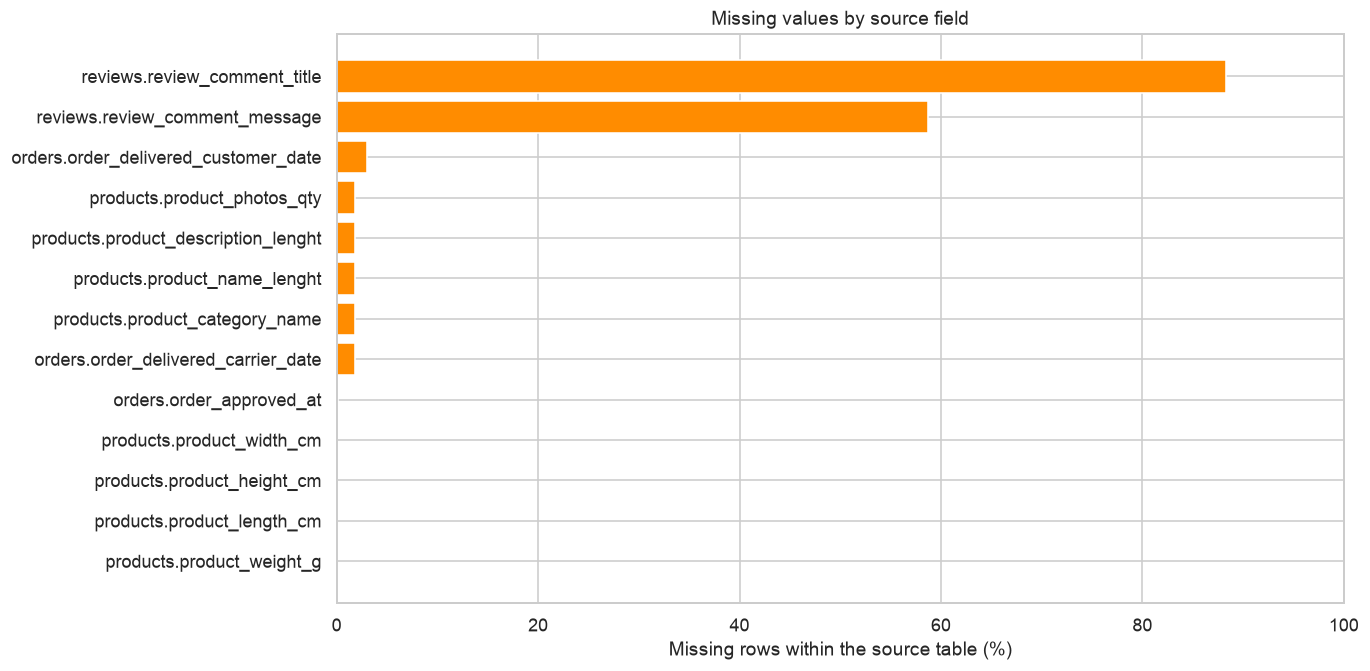

In [6]:
missing_rows = []
for name, df in tables.items():
    for column in df.columns:
        missing_count = df[column].isna().sum()
        if missing_count > 0:
            missing_percent = missing_count / len(df) * 100
            missing_rows.append([name + '.' + column, missing_percent])

missing_summary = pd.DataFrame(missing_rows, columns=['Field', 'Missing percent'])
missing_summary = missing_summary.sort_values('Missing percent')

plt.figure(figsize=(12, 6))
plt.barh(missing_summary['Field'], missing_summary['Missing percent'], color='darkorange')
plt.title('Missing values by source field')
plt.xlabel('Missing rows within the source table (%)')
plt.xlim(0, 100)
plt.tight_layout()
plt.show()


**Reading the chart:** missing review text is different from a missing review score. Missing delivery dates mean the delivery outcome is not observed. We do not fill either type of missing value.


In [7]:
keys = {
    'orders': ['order_id'],
    'items': ['order_id', 'order_item_id'],
    'payments': ['order_id', 'payment_sequential'],
    'reviews': ['review_id', 'order_id'],
    'customers': ['customer_id'],
    'products': ['product_id'],
    'sellers': ['seller_id'],
    'translation': ['product_category_name']
}

duplicate_rows = []
for name, df in tables.items():
    exact_duplicates = df.duplicated().sum()
    key_duplicates = None
    if name in keys:
        key_duplicates = df.duplicated(subset=keys[name]).sum()
    duplicate_rows.append([name, exact_duplicates, key_duplicates])

duplicate_summary = pd.DataFrame(duplicate_rows,
    columns=['Table', 'Exact duplicates', 'Repeated candidate keys'])
display(duplicate_summary)
print('Repeated review IDs alone:', reviews['review_id'].duplicated().sum())


Repeated review IDs alone: 814


,Table,Exact duplicates,Repeated candidate keys
0,orders,0,0.0
1,items,0,0.0
2,payments,0,0.0
3,reviews,0,0.0
4,customers,0,0.0
5,products,0,0.0
6,sellers,0,0.0
7,geolocation,261831,NaN
8,translation,0,0.0


**Decision:** do not delete source rows. Several items, payments or reviews can legitimately belong to one order. Geography also contains repeated observations. Only a plot-specific geography view is aggregated later.

### Do child records point to existing parent records?

`isin()` checks whether a value exists in another column. We count non-missing values without a matching parent; missing keys are counted separately.


In [8]:
relationships = [
    ('orders', 'customer_id', 'customers', 'customer_id'),
    ('items', 'order_id', 'orders', 'order_id'),
    ('payments', 'order_id', 'orders', 'order_id'),
    ('reviews', 'order_id', 'orders', 'order_id'),
    ('items', 'product_id', 'products', 'product_id'),
    ('items', 'seller_id', 'sellers', 'seller_id'),
    ('products', 'product_category_name', 'translation', 'product_category_name'),
    ('customers', 'customer_zip_code_prefix', 'geolocation', 'geolocation_zip_code_prefix'),
    ('sellers', 'seller_zip_code_prefix', 'geolocation', 'geolocation_zip_code_prefix')
]

relationship_rows = []
for child, child_key, parent, parent_key in relationships:
    child_values = tables[child][child_key]
    parent_values = tables[parent][parent_key]
    unmatched = child_values.notna() & ~child_values.isin(parent_values)
    label = child + '.' + child_key + ' → ' + parent + '.' + parent_key
    relationship_rows.append([label, child_values.notna().sum(),
                              child_values.isna().sum(), unmatched.sum()])

relationship_summary = pd.DataFrame(relationship_rows,
    columns=['Relationship', 'Non-null rows', 'Missing keys', 'Unmatched non-null rows'])
display(relationship_summary)


,Relationship,Non-null rows,Missing keys,Unmatched non-null rows
0,orders.customer_id → customers.customer_id,99441,0,0
1,items.order_id → orders.order_id,112650,0,0
2,payments.order_id → orders.order_id,103886,0,0
3,reviews.order_id → orders.order_id,99224,0,0
4,items.product_id → products.product_id,112650,0,0
5,items.seller_id → sellers.seller_id,112650,0,0
6,products.product_category_name → translation.p...,32341,610,13
7,customers.customer_zip_code_prefix → geolocati...,99441,0,278
8,sellers.seller_zip_code_prefix → geolocation.g...,3095,0,7


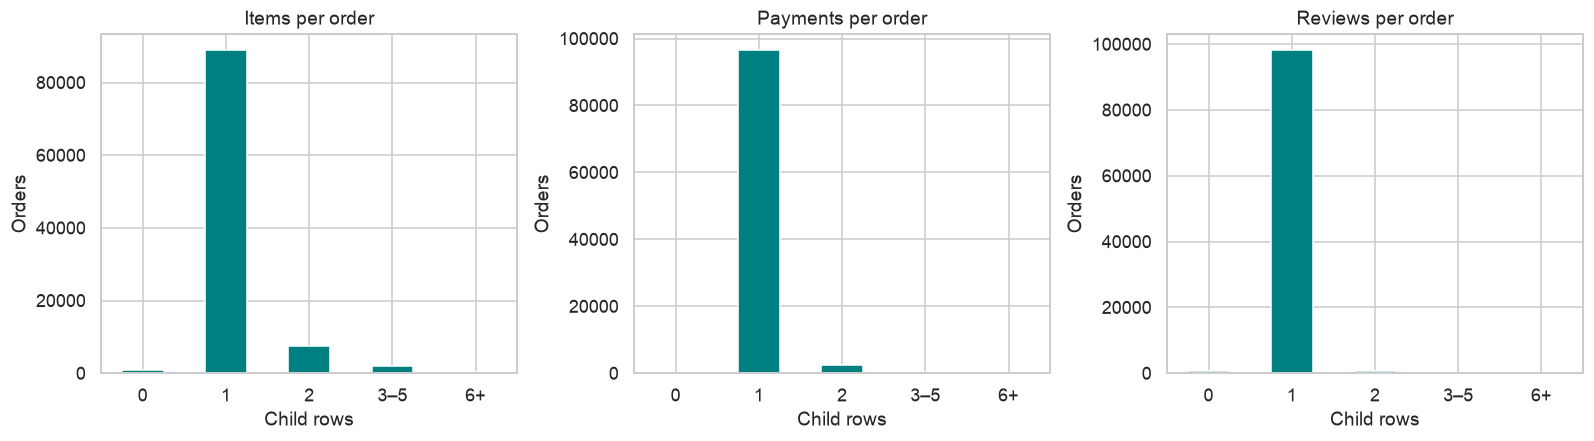

,Table,Orders with rows,Orders without rows,Orders with multiple rows,Maximum rows
0,items,98666,775,9803,21
1,payments,99440,1,2961,29
2,reviews,98673,768,547,3


In [9]:
# Count child rows per order, including orders with no child rows.
# Zero here is a count of absent rows, not an imputed payment or score.
child_summary = []
plt.figure(figsize=(14, 4))
plot_number = 1

for name in ['items', 'payments', 'reviews']:
    counts = tables[name].groupby('order_id').size()
    child_summary.append([name, len(counts), len(orders) - len(counts),
                          (counts > 1).sum(), counts.max()])
    all_counts = counts.reindex(orders['order_id'], fill_value=0)
    groups = pd.cut(all_counts, bins=[-1, 0, 1, 2, 5, np.inf],
                    labels=['0', '1', '2', '3–5', '6+'])
    group_counts = groups.value_counts(sort=False)
    plt.subplot(1, 3, plot_number)
    group_counts.plot(kind='bar', color='teal', rot=0)
    plt.title(name.title() + ' per order')
    plt.xlabel('Child rows')
    plt.ylabel('Orders')
    plot_number = plot_number + 1

plt.tight_layout()
plt.show()
child_summary = pd.DataFrame(child_summary,
    columns=['Table', 'Orders with rows', 'Orders without rows',
             'Orders with multiple rows', 'Maximum rows'])
display(child_summary)


**Why this matters:** merging raw items with raw payments can multiply each item by every payment for that order. We will summarize each child table separately before joining it to orders.

## 3. Check date and value issues

We convert date strings in working copies so we can calculate time differences. `errors='coerce'` returns a missing timestamp if parsing fails; failures are counted, not hidden. We preserve source wall time because the source timezone is unknown.


In [10]:
orders = tables['orders'].copy()
items = tables['items'].copy()
reviews = tables['reviews'].copy()

order_dates = ['order_purchase_timestamp', 'order_approved_at',
               'order_delivered_carrier_date', 'order_delivered_customer_date',
               'order_estimated_delivery_date']
date_checks = []

for column in order_dates:
    original_values = orders[column]
    parsed_values = pd.to_datetime(original_values, errors='coerce')
    failures = original_values.notna() & parsed_values.isna()
    date_checks.append([column, failures.sum(), parsed_values.min(), parsed_values.max()])
    orders[column] = parsed_values

for column in ['review_creation_date', 'review_answer_timestamp']:
    original_values = reviews[column]
    parsed_values = pd.to_datetime(original_values, errors='coerce')
    failures = original_values.notna() & parsed_values.isna()
    date_checks.append([column, failures.sum(), parsed_values.min(), parsed_values.max()])
    reviews[column] = parsed_values

original_values = items['shipping_limit_date']
parsed_values = pd.to_datetime(original_values, errors='coerce')
failures = original_values.notna() & parsed_values.isna()
date_checks.append(['shipping_limit_date', failures.sum(), parsed_values.min(), parsed_values.max()])
items['shipping_limit_date'] = parsed_values

date_checks = pd.DataFrame(date_checks, columns=['Column', 'Parse failures', 'First date', 'Last date'])
display(date_checks)


,Column,Parse failures,First date,Last date
0,order_purchase_timestamp,0,2016-09-04 21:15:19,2018-10-17 17:30:18
1,order_approved_at,0,2016-09-15 12:16:38,2018-09-03 17:40:06
2,order_delivered_carrier_date,0,2016-10-08 10:34:01,2018-09-11 19:48:28
3,order_delivered_customer_date,0,2016-10-11 13:46:32,2018-10-17 13:22:46
4,order_estimated_delivery_date,0,2016-09-30 00:00:00,2018-11-12 00:00:00
5,review_creation_date,0,2016-10-02 00:00:00,2018-08-31 00:00:00
6,review_answer_timestamp,0,2016-10-07 18:32:28,2018-10-29 12:27:35
7,shipping_limit_date,0,2016-09-19 00:15:34,2020-04-09 22:35:08


In [11]:
# Separate named conditions are easier to inspect than one large filter.
approval_before_purchase = orders['order_approved_at'] < orders['order_purchase_timestamp']
carrier_before_purchase = orders['order_delivered_carrier_date'] < orders['order_purchase_timestamp']
carrier_before_approval = orders['order_delivered_carrier_date'] < orders['order_approved_at']
delivery_before_carrier = orders['order_delivered_customer_date'] < orders['order_delivered_carrier_date']

delivered_without_date = (orders['order_status'] == 'delivered') & orders['order_delivered_customer_date'].isna()
other_status_with_date = (orders['order_status'] != 'delivered') & orders['order_delivered_customer_date'].notna()

review_dates = orders[['order_id', 'order_purchase_timestamp', 'order_delivered_customer_date']]
review_join = reviews.merge(review_dates, on='order_id', how='left', validate='many_to_one')
review_before_purchase = review_join['review_answer_timestamp'] < review_join['order_purchase_timestamp']

issues = pd.DataFrame({
    'Issue': ['Approval before purchase', 'Carrier before purchase', 'Carrier before approval',
              'Delivery before carrier', 'Delivered status without delivery date',
              'Other status with delivery date', 'Review answer before purchase',
              'Zero product weight', 'Zero payment amount', 'Zero installments',
              'Shipping deadline after 2018'],
    'Affected rows': [approval_before_purchase.sum(), carrier_before_purchase.sum(),
                      carrier_before_approval.sum(), delivery_before_carrier.sum(),
                      delivered_without_date.sum(), other_status_with_date.sum(),
                      review_before_purchase.sum(), (products['product_weight_g'] == 0).sum(),
                      (payments['payment_value'] == 0).sum(),
                      (payments['payment_installments'] == 0).sum(),
                      (items['shipping_limit_date'] > '2018-12-31').sum()],
    'Row type': ['orders', 'orders', 'orders', 'orders', 'orders', 'orders',
                 'reviews', 'products', 'payments', 'payments', 'items']
})
display(issues)


,Issue,Affected rows,Row type
0,Approval before purchase,0,orders
1,Carrier before purchase,166,orders
2,Carrier before approval,1359,orders
3,Delivery before carrier,23,orders
4,Delivered status without delivery date,8,orders
5,Other status with delivery date,6,orders
6,Review answer before purchase,63,reviews
7,Zero product weight,4,products
8,Zero payment amount,9,payments
9,Zero installments,2,payments


**Handling:** these counts can overlap and must not be added together. No order is removed globally. Negative time intervals are excluded only from their duration chart. Missing delivery stays unknown. Pre-purchase answers are excluded only from the valid first-review analysis. Zero weights are excluded only from the positive-weight relationship plot. Payment anomalies and unusual deadlines remain in the source.

## 4. Build one descriptive row per order

### Step 1: summarize each child table

In `agg()`, each line names an output column and the source calculation. For example, `item_value=('price', 'sum')` adds item prices within an order. These summaries are for EDA, not a model feature table.


In [12]:
item_by_order = items.groupby('order_id').agg(
    item_count=('order_item_id', 'size'),
    product_count=('product_id', 'nunique'),
    seller_count=('seller_id', 'nunique'),
    item_value=('price', 'sum'),
    freight_value=('freight_value', 'sum')
)

payment_by_order = payments.groupby('order_id').agg(
    payment_value=('payment_value', 'sum'),
    payment_rows=('payment_sequential', 'size')
)

review_counts = reviews.groupby('order_id').size()
review_counts.name = 'review_rows'

print('Orders with item rows:', len(item_by_order))
print('Orders with payment rows:', len(payment_by_order))


Orders with item rows: 98666
Orders with payment rows: 99440


### Step 2: select one valid answer per order

Keep answers at or after purchase, sort by answer time, then keep the first answer for each order. Review ID breaks ties. `drop_duplicates` is used only to define this order-level view; no source review is deleted. The raw review distribution still uses every source review row.


In [13]:
valid_answer = review_join['review_answer_timestamp'] >= review_join['order_purchase_timestamp']
valid_review_rows = review_join.loc[valid_answer].copy()
first_review = valid_review_rows.sort_values(['review_answer_timestamp', 'review_id'])
first_review = first_review.drop_duplicates(subset='order_id', keep='first')

print('Raw review rows:', len(reviews))
print('Orders with a valid first answer:', len(first_review))


Raw review rows: 99224
Orders with a valid first answer: 98613


### Step 3: merge one table at a time

A left join keeps every order. `validate='one_to_one'` raises an error if the join unexpectedly multiplies order rows. Missing child totals are left missing, not filled with zero.


In [14]:
order_view = orders.merge(customers, on='customer_id', how='left', validate='one_to_one')
order_view = order_view.merge(item_by_order, on='order_id', how='left', validate='one_to_one')
order_view = order_view.merge(payment_by_order, on='order_id', how='left', validate='one_to_one')
order_view = order_view.merge(review_counts, on='order_id', how='left', validate='one_to_one')

review_columns = first_review[['order_id', 'review_score', 'review_answer_timestamp']]
order_view = order_view.merge(review_columns, on='order_id', how='left', validate='one_to_one')

print('Source orders:', len(orders))
print('Rows after joining:', len(order_view))
print('Order IDs are unique:', order_view['order_id'].is_unique)


Source orders: 99441
Rows after joining: 99441
Order IDs are unique: True


In [15]:
# Elapsed time preserves hours and minutes by converting seconds to days.
delivery_time = order_view['order_delivered_customer_date'] - order_view['order_purchase_timestamp']
promise_time = order_view['order_estimated_delivery_date'] - order_view['order_purchase_timestamp']
order_view['delivery_days'] = delivery_time.dt.total_seconds() / 86400
order_view['promise_days'] = promise_time.dt.total_seconds() / 86400

# normalize() removes the time of day, so this compares calendar dates.
delivery_date = order_view['order_delivered_customer_date'].dt.normalize()
promise_date = order_view['order_estimated_delivery_date'].dt.normalize()
order_view['delay_calendar_days'] = (delivery_date - promise_date).dt.days

valid_delivery = (order_view['delivery_days'] >= 0) & order_view['order_estimated_delivery_date'].notna()
deliveries = order_view.loc[valid_delivery].copy()
deliveries['late_calendar'] = deliveries['delay_calendar_days'] > 0
# Only this observed-delivery subset gets a True/False late flag.
# Other orders stay in order_view without being labeled on time.


In [16]:
# Check that the joins preserved independent source totals.
assert len(order_view) == len(orders)
assert order_view['order_id'].is_unique
assert np.isclose(order_view['item_value'].sum(), items['price'].sum())
assert np.isclose(order_view['freight_value'].sum(), items['freight_value'].sum())
assert np.isclose(order_view['payment_value'].sum(), payments['payment_value'].sum())

metrics = pd.DataFrame({
    'Metric': ['Placed orders', 'Distinct observed buyers', 'Item value (BRL)',
               'Freight charges (BRL)', 'Payment snapshot total (BRL)',
               'Mean item value per order with items (BRL)', 'Observed delivery coverage (%)',
               'Calendar-late among observed deliveries (%)'],
    'Value': [len(order_view), customers['customer_unique_id'].nunique(), items['price'].sum(),
              items['freight_value'].sum(), payments['payment_value'].sum(),
              item_by_order['item_value'].mean(), len(deliveries) / len(order_view) * 100,
              deliveries['late_calendar'].mean() * 100]
})
display(metrics.round(2))
print('Join-count and monetary-total checks passed.')


Join-count and monetary-total checks passed.


,Metric,Value
0,Placed orders,99441.00
1,Distinct observed buyers,96096.00
2,Item value (BRL),13591643.70
3,Freight charges (BRL),2251909.54
4,Payment snapshot total (BRL),16008872.12
5,Mean item value per order with items (BRL),137.75
6,Observed delivery coverage (%),97.02
7,Calendar-late among observed deliveries (%),6.77


All statuses are included in placed orders and recorded item totals. Average item order value uses only orders with item rows. Delivery coverage uses all orders; lateness uses only valid observed deliveries. Item value is not profit, freight is a charge rather than a cost, and payments are undated snapshot records.

## 5. Explore time patterns and statuses

First put purchase time on the index. `resample('MS')` then groups rows by calendar month. `size()` counts rows, including zero counts in empty months. `sum(min_count=1)` leaves a month with no known item amounts as unknown.


Highest recorded month: November 2017
Orders in that month: 7544


,orders,item_value
order_purchase_timestamp,,
2016-09-01,4,267.36
2016-10-01,324,49507.66
2016-11-01,0,NaN
2016-12-01,1,10.90
2017-01-01,800,120312.87
2017-02-01,1780,247303.02
2017-03-01,2682,374344.30
2017-04-01,2404,359927.23
2017-05-01,3700,506071.14


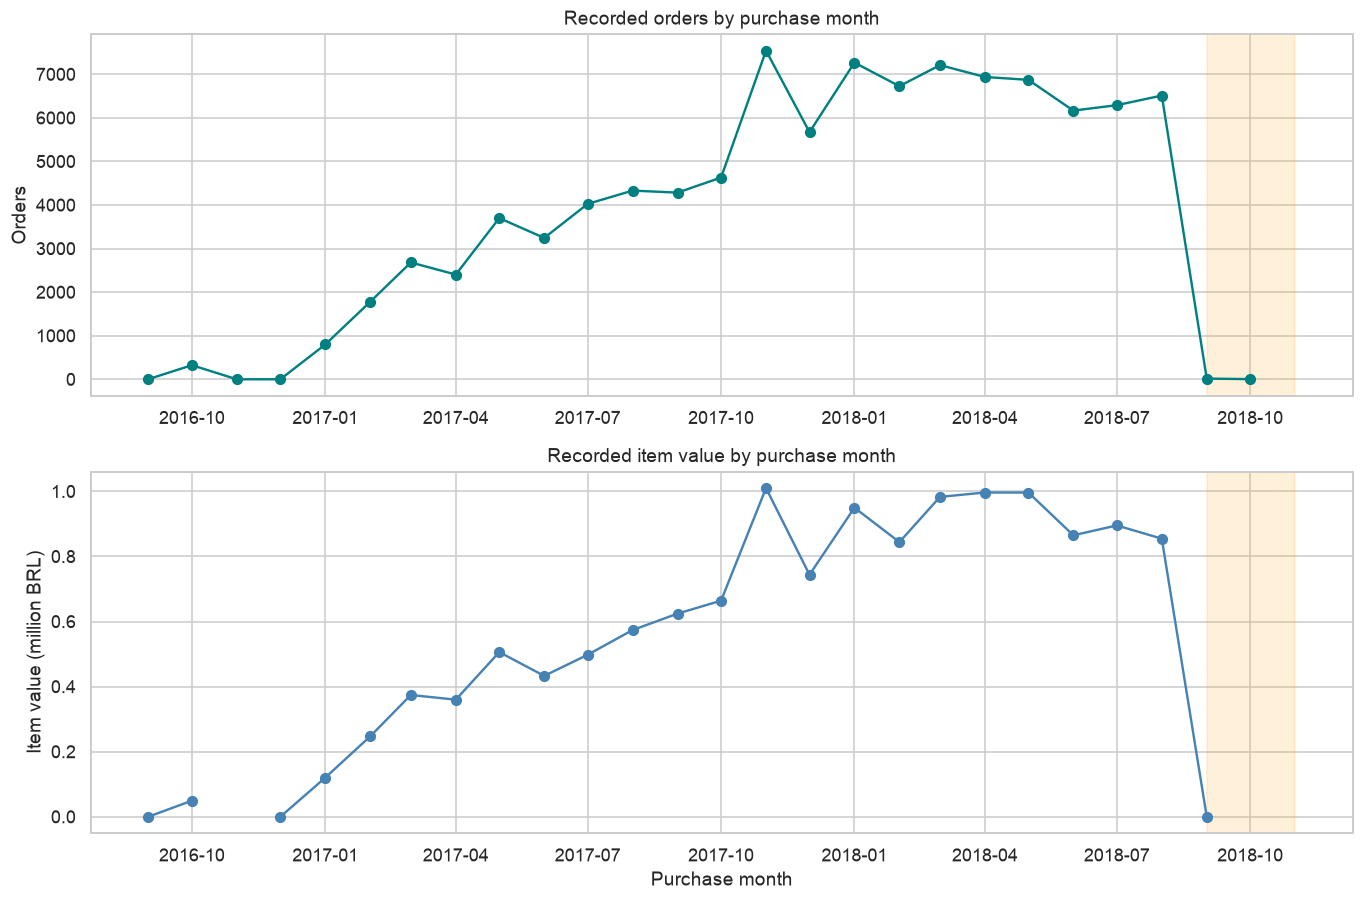

In [17]:
orders_by_date = order_view.set_index('order_purchase_timestamp')
monthly_orders = orders_by_date.resample('MS').size()
monthly_value = orders_by_date['item_value'].resample('MS').sum(min_count=1)

monthly = pd.DataFrame({'orders': monthly_orders, 'item_value': monthly_value})
display(monthly.round(2))

plt.figure(figsize=(12, 8))
plt.subplot(2, 1, 1)
plt.plot(monthly.index, monthly['orders'], marker='o', color='teal')
plt.title('Recorded orders by purchase month')
plt.ylabel('Orders')
plt.axvspan(pd.Timestamp('2018-09-01'), pd.Timestamp('2018-11-01'), color='orange', alpha=0.15)
plt.subplot(2, 1, 2)
plt.plot(monthly.index, monthly['item_value'] / 1000000, marker='o', color='steelblue')
plt.title('Recorded item value by purchase month')
plt.xlabel('Purchase month')
plt.ylabel('Item value (million BRL)')
plt.axvspan(pd.Timestamp('2018-09-01'), pd.Timestamp('2018-11-01'), color='orange', alpha=0.15)
plt.tight_layout()
plt.show()

peak_month = monthly['orders'].idxmax()
print('Highest recorded month:', peak_month.strftime('%B %Y'))
print('Orders in that month:', monthly.loc[peak_month, 'orders'])


**Interpretation:** the orange area is the sparse September–October 2018 tail. A collapse in recorded rows does not prove a collapse in demand. The outer months are partial based on observed bounds. No causal growth claim is made.


Calendar weeks: 112
Zero-order weeks: 11


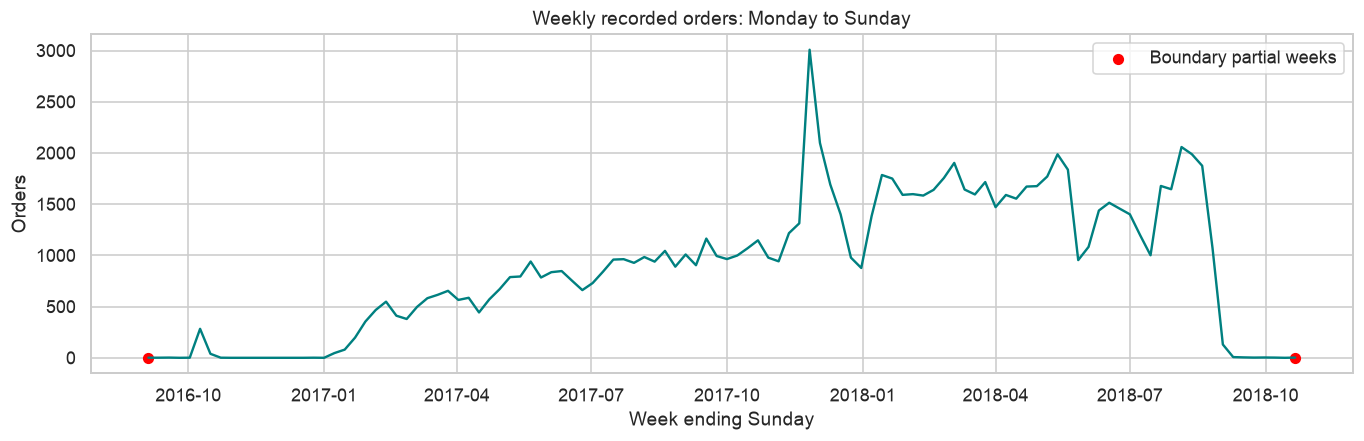

In [18]:
weekly = orders_by_date.resample('W-SUN').size()
first_day = order_view['order_purchase_timestamp'].min().normalize()
last_day = order_view['order_purchase_timestamp'].max().normalize()
week_start = weekly.index - pd.Timedelta(days=6)
complete_week = (week_start >= first_day) & (weekly.index <= last_day)

plt.figure(figsize=(12, 4))
plt.plot(weekly.index, weekly.values, color='teal')
plt.scatter(weekly.index[~complete_week], weekly.values[~complete_week], color='red', label='Boundary partial weeks')
plt.title('Weekly recorded orders: Monday to Sunday')
plt.xlabel('Week ending Sunday')
plt.ylabel('Orders')
plt.legend()
plt.tight_layout()
plt.show()
print('Calendar weeks:', len(weekly))
print('Zero-order weeks:', (weekly == 0).sum())


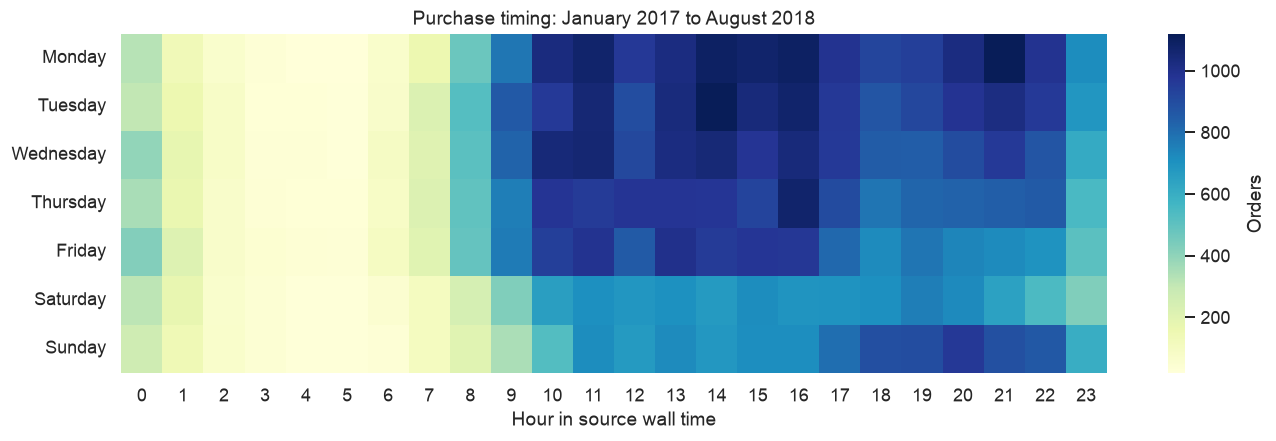

In [19]:
# Use the same comparison window as the original notebook.
in_comparison_window = (order_view['order_purchase_timestamp'] >= '2017-01-01') & (order_view['order_purchase_timestamp'] < '2018-09-01')
purchase_times = order_view.loc[in_comparison_window, 'order_purchase_timestamp']

weekday = purchase_times.dt.dayofweek
hour = purchase_times.dt.hour
purchase_heatmap = pd.crosstab(weekday, hour)
purchase_heatmap = purchase_heatmap.reindex(index=range(7), columns=range(24), fill_value=0)
purchase_heatmap.index = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(12, 4))
sns.heatmap(purchase_heatmap, cmap='YlGnBu', cbar_kws={'label': 'Orders'})
plt.title('Purchase timing: January 2017 to August 2018')
plt.xlabel('Hour in source wall time')
plt.ylabel('')
plt.tight_layout()
plt.show()


The heatmap uses recorded counts, not rates per available weekday-hour. Hours are not converted to another timezone. Empty time bins contain zero recorded events; no source value has been imputed.


,Orders,Share percent
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


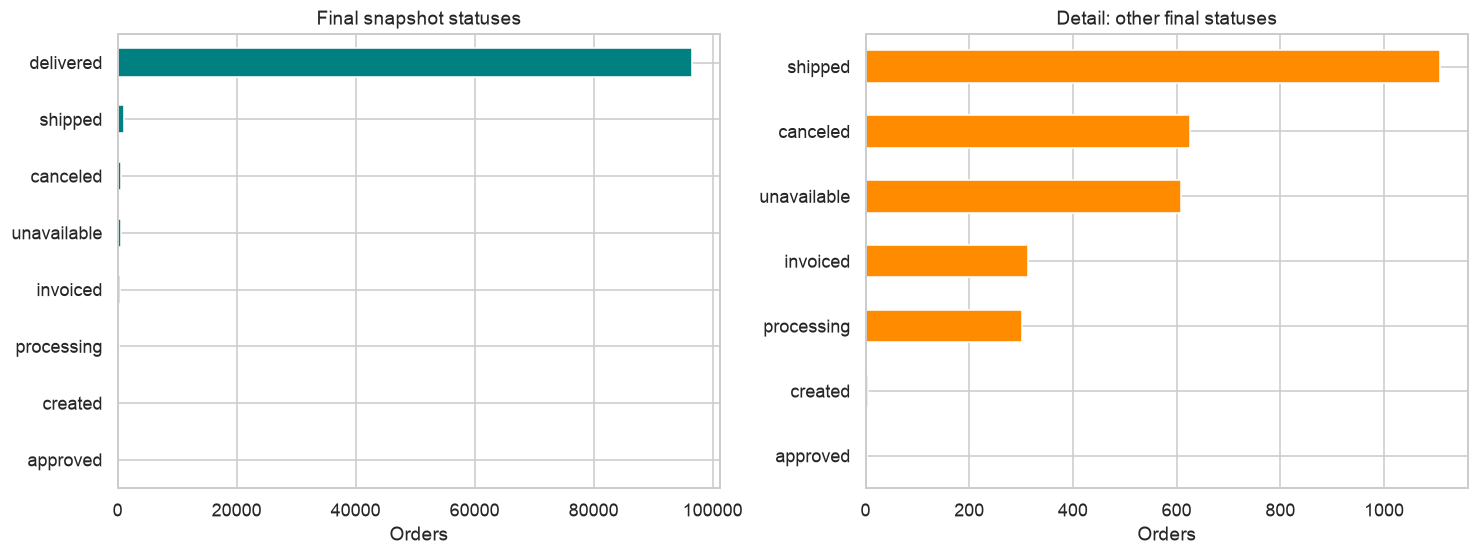

In [20]:
status_counts = orders['order_status'].value_counts()
status_summary = pd.DataFrame({'Orders': status_counts})
status_summary['Share percent'] = status_summary['Orders'] / len(orders) * 100
display(status_summary.round(2))

plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
status_counts.sort_values().plot(kind='barh', color='teal')
plt.title('Final snapshot statuses')
plt.xlabel('Orders')
plt.ylabel('')
plt.subplot(1, 2, 2)
other_statuses = status_counts.drop('delivered', errors='ignore')
other_statuses.sort_values().plot(kind='barh', color='darkorange')
plt.title('Detail: other final statuses')
plt.xlabel('Orders')
plt.ylabel('')
plt.tight_layout()
plt.show()


Final status is a snapshot label. The data does not provide cancellation timestamps or every historical transition, so this is not an operational funnel.

## 6. Explore basket value and freight

Use orders that actually have item rows. Freight share is `freight / (item value + freight)`. Log scales show the long tail without removing large orders.


In [21]:
has_items = order_view['item_value'].notna()
baskets = order_view.loc[has_items].copy()
baskets['freight_share_pct'] = baskets['freight_value'] / (baskets['item_value'] + baskets['freight_value']) * 100

basket_columns = ['item_value', 'freight_value', 'item_count', 'freight_share_pct']
display(baskets[basket_columns].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2))
print('Orders with item rows:', len(baskets))
print('Orders without item rows:', len(order_view) - len(baskets))
print('Median item order value:', round(baskets['item_value'].median(), 2))
print('Mean item order value:', round(baskets['item_value'].mean(), 2))


Orders with item rows: 98666
Orders without item rows: 775
Median item order value: 86.9
Mean item order value: 137.75


,item_value,freight_value,item_count,freight_share_pct
count,98666.00,98666.00,98666.00,98666.00
mean,137.75,22.82,1.14,20.88
std,210.65,21.65,0.54,12.57
min,0.85,0.00,1.00,0.00
50%,86.90,17.17,1.00,18.33
90%,269.90,39.50,1.00,38.37
95%,399.90,54.96,2.00,45.63
99%,998.90,104.98,3.00,59.38
max,13440.00,1794.96,21.00,95.55


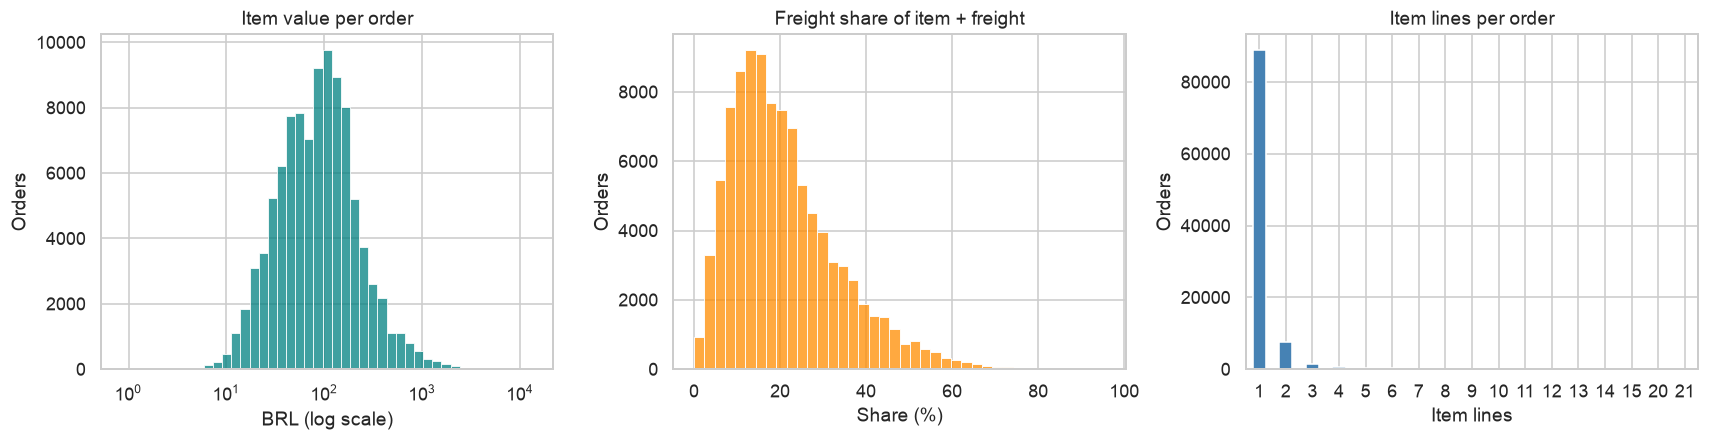

In [22]:
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
sns.histplot(baskets['item_value'], bins=45, log_scale=True, color='teal')
plt.title('Item value per order')
plt.xlabel('BRL (log scale)')
plt.ylabel('Orders')
plt.subplot(1, 3, 2)
sns.histplot(baskets['freight_share_pct'], bins=40, color='darkorange')
plt.title('Freight share of item + freight')
plt.xlabel('Share (%)')
plt.ylabel('Orders')
plt.subplot(1, 3, 3)
basket_sizes = baskets['item_count'].value_counts().sort_index()
basket_sizes.index = basket_sizes.index.astype(int)
basket_sizes.plot(kind='bar', color='steelblue', rot=0)
plt.title('Item lines per order')
plt.xlabel('Item lines')
plt.ylabel('Orders')
plt.tight_layout()
plt.show()


Orders shown: 98328
Zero-freight orders excluded from this plot only: 338


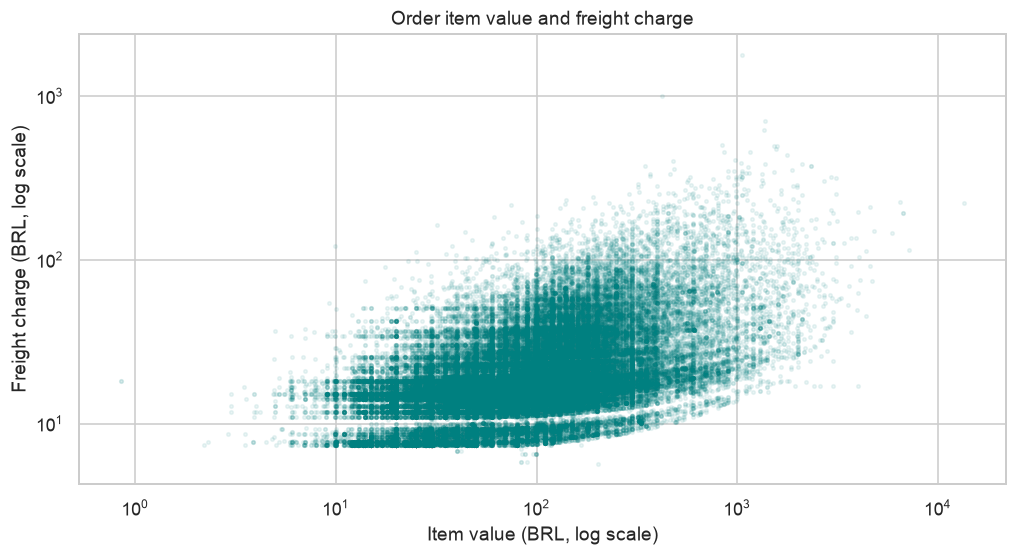

In [23]:
# Positive freight is required only for this log-axis chart.
positive_freight = baskets.loc[baskets['freight_value'] > 0]

plt.figure(figsize=(9, 5))
plt.scatter(positive_freight['item_value'], positive_freight['freight_value'], s=5, alpha=0.08, color='teal')
plt.xscale('log')
plt.yscale('log')
plt.title('Order item value and freight charge')
plt.xlabel('Item value (BRL, log scale)')
plt.ylabel('Freight charge (BRL, log scale)')
plt.tight_layout()
plt.show()
print('Orders shown:', len(positive_freight))
print('Zero-freight orders excluded from this plot only:', (baskets['freight_value'] == 0).sum())


**Interpretation:** compare the mean and median to see the effect of large orders. All large values remain in totals. The scatter uses the same eligible orders as the original density plot; transparency handles overlapping points. An association does not explain the cause of freight pricing.

## 7. Explore delivery experience

The `deliveries` table contains only valid observed deliveries. We compare calendar-day lateness with exact-timestamp lateness, because promised dates are recorded at midnight.


In [24]:
calendar_late = deliveries['late_calendar']
exact_late = deliveries['order_delivered_customer_date'] > deliveries['order_estimated_delivery_date']

late_comparison = pd.DataFrame({
    'Rule': ['After promised calendar day', 'After exact estimated timestamp'],
    'Eligible deliveries': [len(deliveries), len(deliveries)],
    'Late deliveries': [calendar_late.sum(), exact_late.sum()],
    'Late percent': [calendar_late.mean() * 100, exact_late.mean() * 100]
})
display(late_comparison.round(2))
print('Orders without an eligible delivery label:', len(order_view) - len(deliveries))
print('Median delivery days:', round(deliveries['delivery_days'].median(), 1))
print('90th percentile delivery days:', round(deliveries['delivery_days'].quantile(0.9), 1))


Orders without an eligible delivery label: 2965
Median delivery days: 10.2
90th percentile delivery days: 23.1


,Rule,Eligible deliveries,Late deliveries,Late percent
0,After promised calendar day,96476,6535,6.77
1,After exact estimated timestamp,96476,7827,8.11


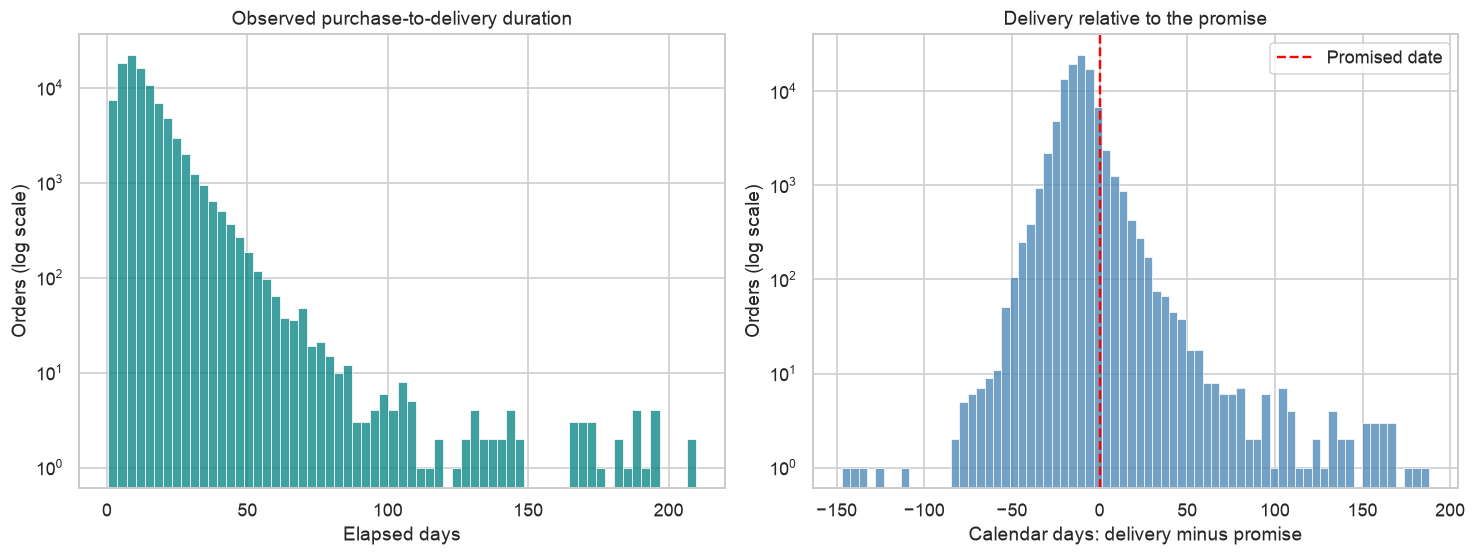

In [25]:
plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
sns.histplot(deliveries['delivery_days'], bins=65, color='teal')
plt.yscale('log')
plt.title('Observed purchase-to-delivery duration')
plt.xlabel('Elapsed days')
plt.ylabel('Orders (log scale)')
plt.subplot(1, 2, 2)
sns.histplot(deliveries['delay_calendar_days'], bins=70, color='steelblue')
plt.axvline(0, color='red', linestyle='--', label='Promised date')
plt.yscale('log')
plt.title('Delivery relative to the promise')
plt.xlabel('Calendar days: delivery minus promise')
plt.ylabel('Orders (log scale)')
plt.legend()
plt.tight_layout()
plt.show()


### Look at each fulfillment interval separately

A nonnegative interval with both endpoints is eligible. An invalid carrier interval does not remove the order from every other analysis. The three segments therefore have different denominators.

An ECDF shows the fraction of eligible records at or below each duration. It keeps the complete distribution visible without trimming long durations.


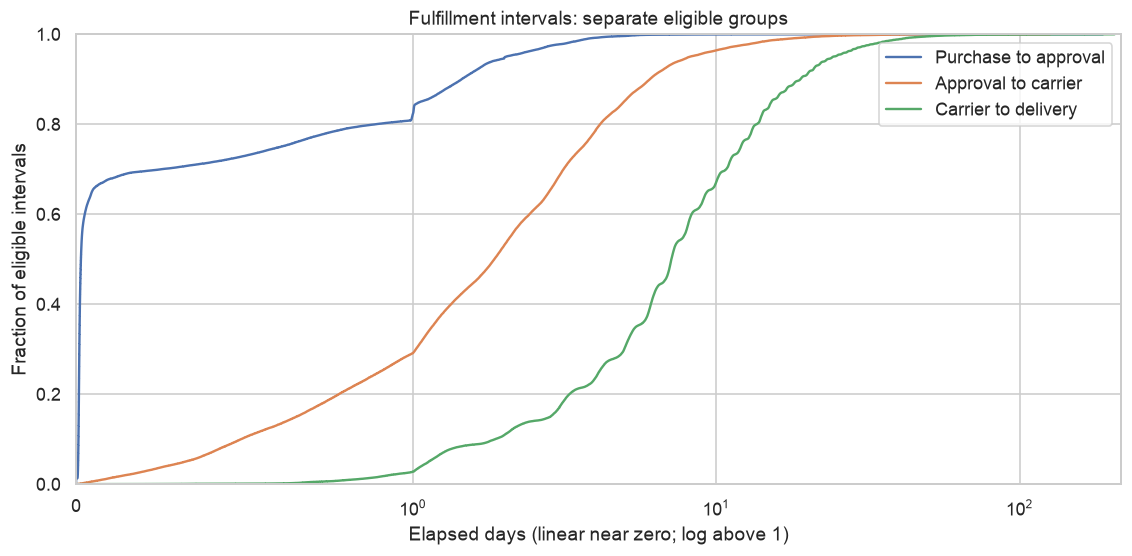

,Interval,Eligible,Missing endpoint,Negative interval,Median days,P90 days
0,Purchase to approval,99281,160,0,0.01,1.44
1,Approval to carrier,96285,1797,1359,1.85,6.03
2,Carrier to delivery,96452,2966,23,7.10,18.90


In [26]:
approval_days = (orders['order_approved_at'] - orders['order_purchase_timestamp']).dt.total_seconds() / 86400
handling_days = (orders['order_delivered_carrier_date'] - orders['order_approved_at']).dt.total_seconds() / 86400
transit_days = (orders['order_delivered_customer_date'] - orders['order_delivered_carrier_date']).dt.total_seconds() / 86400

intervals = {'Purchase to approval': approval_days,
             'Approval to carrier': handling_days,
             'Carrier to delivery': transit_days}
interval_rows = []

plt.figure(figsize=(10, 5))
for label, days in intervals.items():
    eligible_days = days[days >= 0]
    interval_rows.append([label, len(eligible_days), days.isna().sum(), (days < 0).sum(),
                          eligible_days.median(), eligible_days.quantile(0.9)])
    sns.ecdfplot(eligible_days, label=label)

plt.xscale('symlog', linthresh=1)
plt.xlim(left=0)
plt.title('Fulfillment intervals: separate eligible groups')
plt.xlabel('Elapsed days (linear near zero; log above 1)')
plt.ylabel('Fraction of eligible intervals')
plt.legend()
plt.tight_layout()
plt.show()
interval_summary = pd.DataFrame(interval_rows,
    columns=['Interval', 'Eligible', 'Missing endpoint', 'Negative interval', 'Median days', 'P90 days'])
display(interval_summary.round(2))


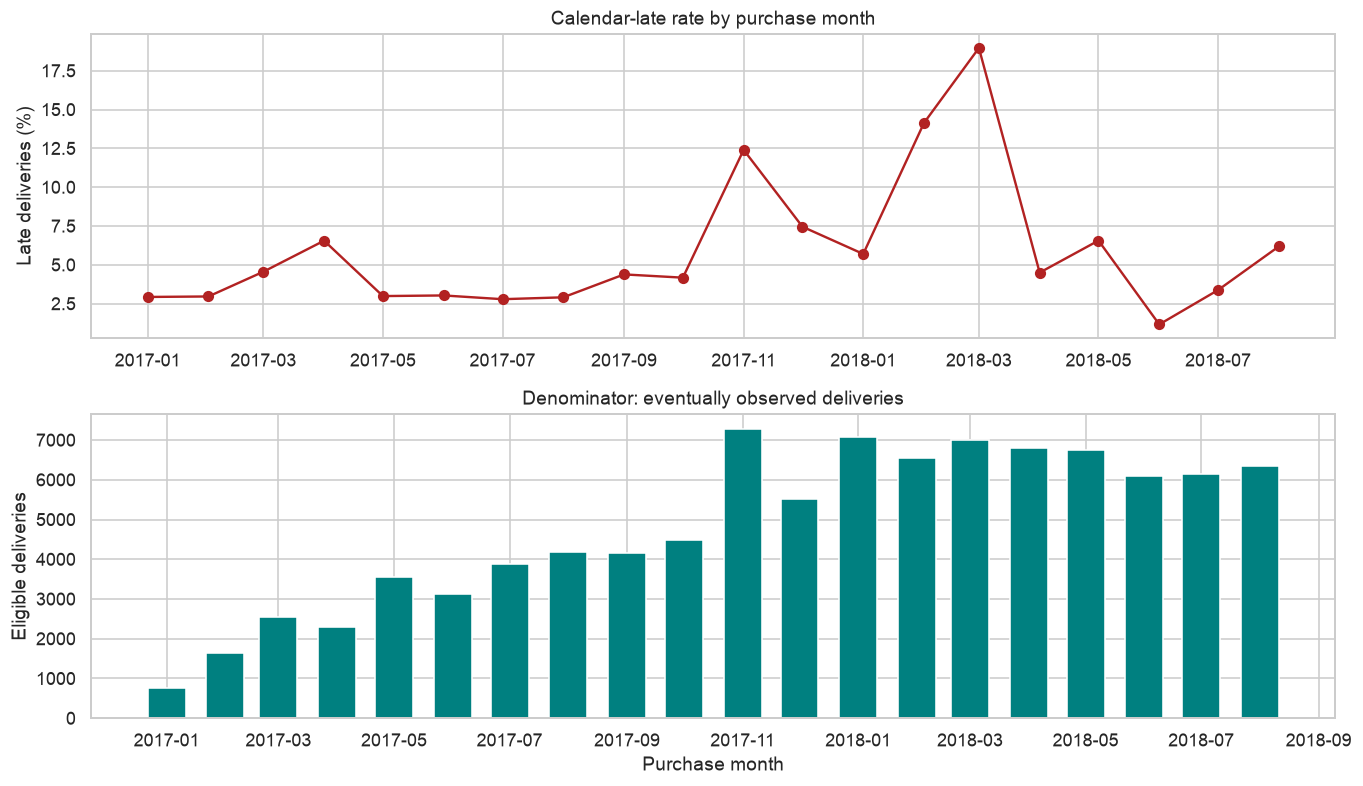

In [27]:
deliveries['purchase_month'] = deliveries['order_purchase_timestamp'].dt.to_period('M')
monthly_delivery = deliveries.groupby('purchase_month').agg(
    deliveries=('order_id', 'size'),
    late=('late_calendar', 'sum'),
    median_days=('delivery_days', 'median')
)
monthly_delivery['late_pct'] = monthly_delivery['late'] / monthly_delivery['deliveries'] * 100
monthly_delivery.index = monthly_delivery.index.to_timestamp()
plot_months = monthly_delivery.loc['2017-01-01':'2018-08-01']

plt.figure(figsize=(12, 7))
plt.subplot(2, 1, 1)
plt.plot(plot_months.index, plot_months['late_pct'], marker='o', color='firebrick')
plt.title('Calendar-late rate by purchase month')
plt.ylabel('Late deliveries (%)')
plt.subplot(2, 1, 2)
plt.bar(plot_months.index, plot_months['deliveries'], width=20, color='teal')
plt.title('Denominator: eventually observed deliveries')
plt.xlabel('Purchase month')
plt.ylabel('Eligible deliveries')
plt.tight_layout()
plt.show()


This monthly comparison uses later observed delivery outcomes for each purchase cohort. It is retrospective, not what was known during that month. Unknown deliveries are not counted as on time, and boundary cohorts may have incomplete follow-up.


## 8. Explore reviews and delivery relationships

Use all review rows for the raw score distribution, and one valid first answer per order for order-level comparisons. A score of 1 or 2 is considered negative. No answer is never converted into a positive score. We summarize whether text exists without displaying customer comments.


Valid first answers: 98613
Negative first-answer percent: 14.64


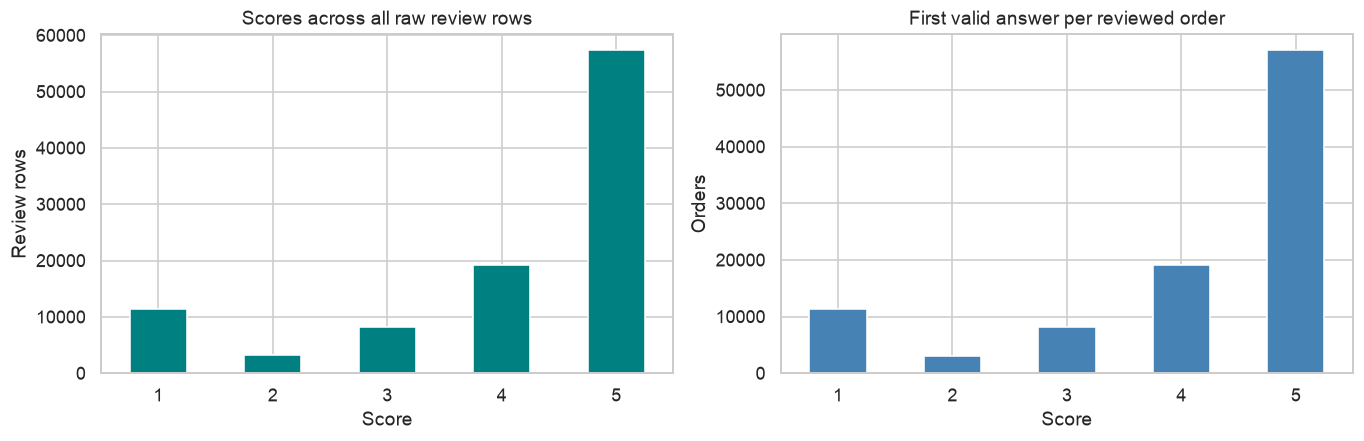

,Field,Review rows,Share percent
0,Title present,11568,11.66
1,Message present,40977,41.30


In [28]:
raw_scores = reviews['review_score'].value_counts().sort_index()
first_scores = first_review['review_score'].value_counts().sort_index()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
raw_scores.plot(kind='bar', color='teal', rot=0)
plt.title('Scores across all raw review rows')
plt.xlabel('Score')
plt.ylabel('Review rows')
plt.subplot(1, 2, 2)
first_scores.plot(kind='bar', color='steelblue', rot=0)
plt.title('First valid answer per reviewed order')
plt.xlabel('Score')
plt.ylabel('Orders')
plt.tight_layout()
plt.show()

negative_first = first_review['review_score'] <= 2
print('Valid first answers:', len(first_review))
print('Negative first-answer percent:', round(negative_first.mean() * 100, 2))
text_coverage = pd.DataFrame({
    'Field': ['Title present', 'Message present'],
    'Review rows': [reviews['review_comment_title'].notna().sum(),
                    reviews['review_comment_message'].notna().sum()],
    'Share percent': [reviews['review_comment_title'].notna().mean() * 100,
                      reviews['review_comment_message'].notna().mean() * 100]
})
display(text_coverage.round(2))


### Compare delivery experience and first-review scores

Start with observed deliveries that also have a valid first answer. Assign the labels in two simple steps. `crosstab(..., normalize='index')` calculates each score's proportion within its delivery group.


In [29]:
review_delivery = deliveries.loc[deliveries['review_score'].notna()].copy()
review_delivery['Delivery experience'] = 'On time / early'
review_delivery.loc[review_delivery['late_calendar'], 'Delivery experience'] = 'Late'
review_delivery['Negative'] = review_delivery['review_score'] <= 2

score_mix = pd.crosstab(review_delivery['Delivery experience'],
                        review_delivery['review_score'], normalize='index') * 100
score_mix.columns = score_mix.columns.astype(int)
negative_by_delivery = review_delivery.groupby('Delivery experience').agg(
    reviewed_orders=('order_id', 'size'),
    negative=('Negative', 'sum')
)
negative_by_delivery['negative_pct'] = negative_by_delivery['negative'] / negative_by_delivery['reviewed_orders'] * 100
display(negative_by_delivery.round(2))


,reviewed_orders,negative,negative_pct
Delivery experience,,,
Late,6382,3979,62.35
On time / early,89445,8284,9.26


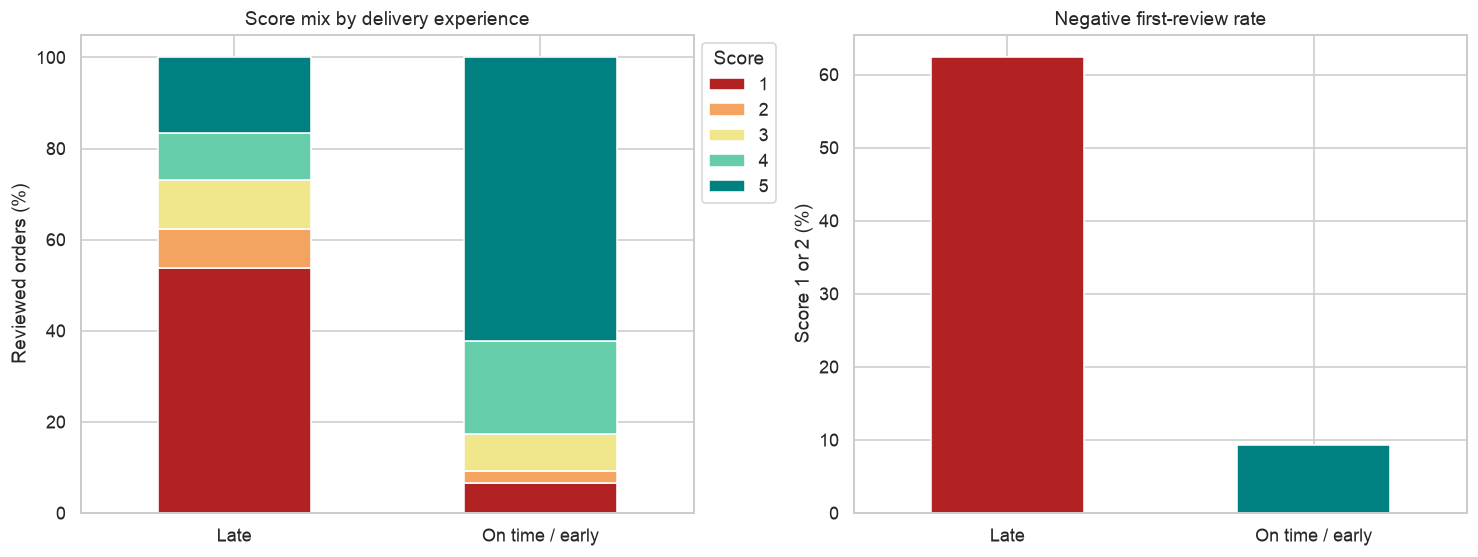

In [30]:
plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
score_mix.plot(kind='bar', stacked=True, ax=plt.gca(), rot=0,
               color=['firebrick', 'sandybrown', 'khaki', 'mediumaquamarine', 'teal'])
plt.title('Score mix by delivery experience')
plt.xlabel('')
plt.ylabel('Reviewed orders (%)')
plt.legend(title='Score', bbox_to_anchor=(1, 1))
plt.subplot(1, 2, 2)
negative_by_delivery['negative_pct'].plot(kind='bar', color=['firebrick', 'teal'], rot=0)
plt.title('Negative first-review rate')
plt.xlabel('')
plt.ylabel('Score 1 or 2 (%)')
plt.tight_layout()
plt.show()


**Interpretation:** this is an association among delivered orders with observed answers, not evidence that delay caused the score. Some answers arrived before delivery. Customers without answers are not represented in the score-rate denominator.


,Timing,Orders
0,Before or at delivery,4763
1,After delivery,91064
2,No observed delivery,2786


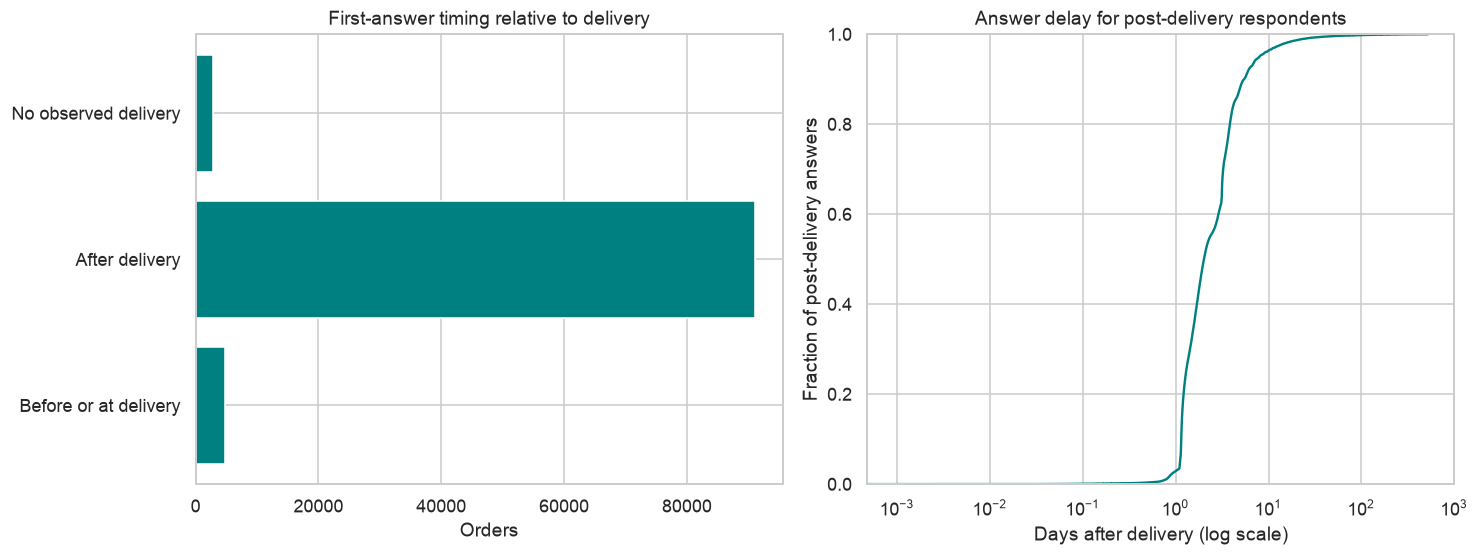

In [31]:
answer_delay = first_review['review_answer_timestamp'] - first_review['order_delivered_customer_date']
answer_delay = answer_delay.dt.total_seconds() / 86400

review_timing = pd.DataFrame({
    'Timing': ['Before or at delivery', 'After delivery', 'No observed delivery'],
    'Orders': [(answer_delay <= 0).sum(), (answer_delay > 0).sum(), answer_delay.isna().sum()]
})
display(review_timing)

plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
plt.barh(review_timing['Timing'], review_timing['Orders'], color='teal')
plt.title('First-answer timing relative to delivery')
plt.xlabel('Orders')
plt.subplot(1, 2, 2)
post_delivery_delay = answer_delay[answer_delay > 0]
sns.ecdfplot(post_delivery_delay, color='teal')
plt.xscale('log')
plt.title('Answer delay for post-delivery respondents')
plt.xlabel('Days after delivery (log scale)')
plt.ylabel('Fraction of post-delivery answers')
plt.tight_layout()
plt.show()


In [32]:
review_months = order_view.copy()
review_months['month'] = review_months['order_purchase_timestamp'].dt.to_period('M')
review_coverage = review_months.groupby('month').agg(
    orders=('order_id', 'size'),
    reviewed=('review_score', 'count')
)
review_coverage['review_coverage_pct'] = review_coverage['reviewed'] / review_coverage['orders'] * 100
display(review_coverage.loc['2017-01':'2018-08'].round(2))


,orders,reviewed,review_coverage_pct
month,,,
2017-01,800,790,98.75
2017-02,1780,1768,99.33
2017-03,2682,2661,99.22
2017-04,2404,2387,99.29
2017-05,3700,3666,99.08
2017-06,3245,3218,99.17
2017-07,4026,3990,99.11
2017-08,4331,4298,99.24
2017-09,4285,4251,99.21


Review creation is survey metadata, not the time the answer became available. Answer timestamp is used for timing. Review coverage is retrospective and depends on how long orders could be followed.

## 9. Explore payments and reconciliation

Payment types describe payment rows, not unique orders. An order may use more than one method, so order counts by method can overlap. Payments have no settlement timestamps.


,payment_rows,orders,value
payment_type,,,
credit_card,76795,76505,12542084.19
boleto,19784,19784,2869361.27
voucher,5775,3866,379436.87
debit_card,1529,1528,217989.79
not_defined,3,3,0.00


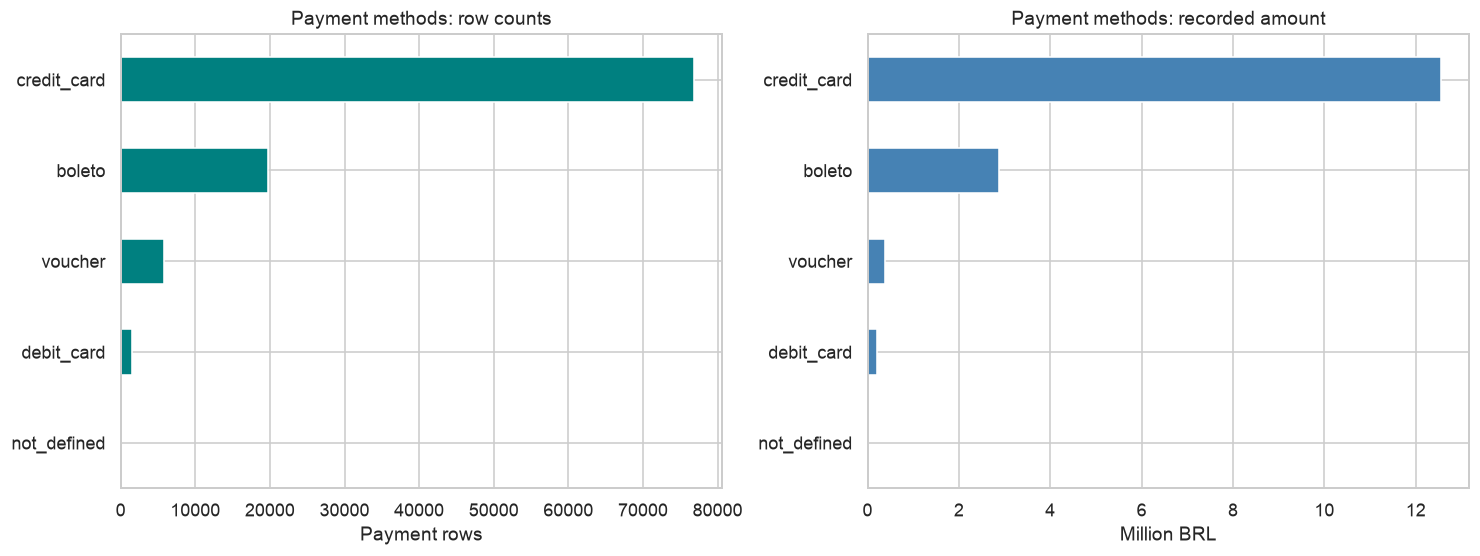

In [33]:
payment_methods = payments.groupby('payment_type').agg(
    payment_rows=('order_id', 'size'),
    orders=('order_id', 'nunique'),
    value=('payment_value', 'sum')
)
payment_methods = payment_methods.sort_values('value', ascending=False)
display(payment_methods.round(2))

plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
payment_methods['payment_rows'].sort_values().plot(kind='barh', color='teal')
plt.title('Payment methods: row counts')
plt.xlabel('Payment rows')
plt.ylabel('')
plt.subplot(1, 2, 2)
method_millions = payment_methods['value'] / 1000000
method_millions.sort_values().plot(kind='barh', color='steelblue')
plt.title('Payment methods: recorded amount')
plt.xlabel('Million BRL')
plt.ylabel('')
plt.tight_layout()
plt.show()


Zero installment rows across all payment types: 2


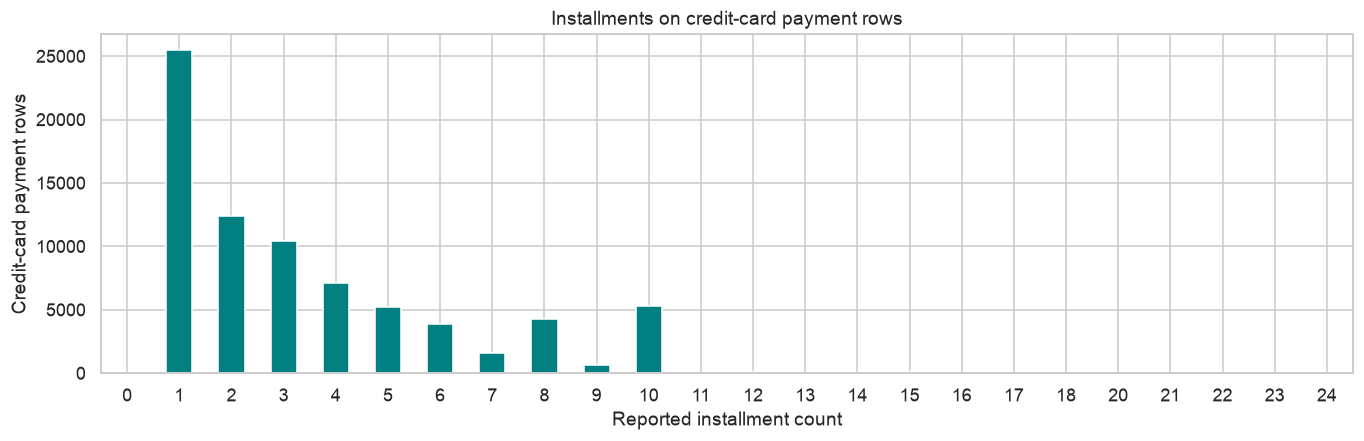

In [34]:
credit_cards = payments.loc[payments['payment_type'] == 'credit_card']
installments = credit_cards['payment_installments'].value_counts().sort_index()

plt.figure(figsize=(12, 4))
installments.plot(kind='bar', color='teal', rot=0)
plt.title('Installments on credit-card payment rows')
plt.xlabel('Reported installment count')
plt.ylabel('Credit-card payment rows')
plt.tight_layout()
plt.show()
print('Zero installment rows across all payment types:', (payments['payment_installments'] == 0).sum())


Zero installment values remain visible; they are not replaced with one.

### Do payment totals match item value plus freight?

Compare only orders with both sides present. Convert totals to integer cents before subtraction to avoid floating-point errors around one cent. This changes calculation precision, not the recorded amounts.


In [35]:
has_both_sides = order_view['item_value'].notna() & order_view['payment_value'].notna()
reconciliation = order_view.loc[has_both_sides, ['order_id', 'item_value', 'freight_value', 'payment_value']].copy()

item_and_freight = reconciliation['item_value'] + reconciliation['freight_value']
reconciliation['item_and_freight_cents'] = (item_and_freight * 100).round().astype('int64')
reconciliation['payment_cents'] = (reconciliation['payment_value'] * 100).round().astype('int64')
reconciliation['difference_brl'] = (reconciliation['payment_cents'] - reconciliation['item_and_freight_cents']) / 100

# Assign the broad group first, then the more specific groups.
reconciliation['Class'] = 'Difference > one cent'
within_one_cent = reconciliation['difference_brl'].abs() <= 0.01
exact_match = reconciliation['difference_brl'] == 0
reconciliation.loc[within_one_cent, 'Class'] = 'Within one cent'
reconciliation.loc[exact_match, 'Class'] = 'Exact match'

different = reconciliation.loc[reconciliation['difference_brl'].abs() > 0.01, 'difference_brl']
print('Orders with both sides:', len(reconciliation))
print('Orders without item rows:', order_view['item_value'].isna().sum())
print('Orders without payment rows:', order_view['payment_value'].isna().sum())
print('Orders differing by more than one cent:', len(different))
print('Net difference in matched orders (BRL):', round(reconciliation['difference_brl'].sum(), 2))


Orders with both sides: 98665
Orders without item rows: 775
Orders without payment rows: 1
Orders differing by more than one cent: 303
Net difference in matched orders (BRL): 2870.39


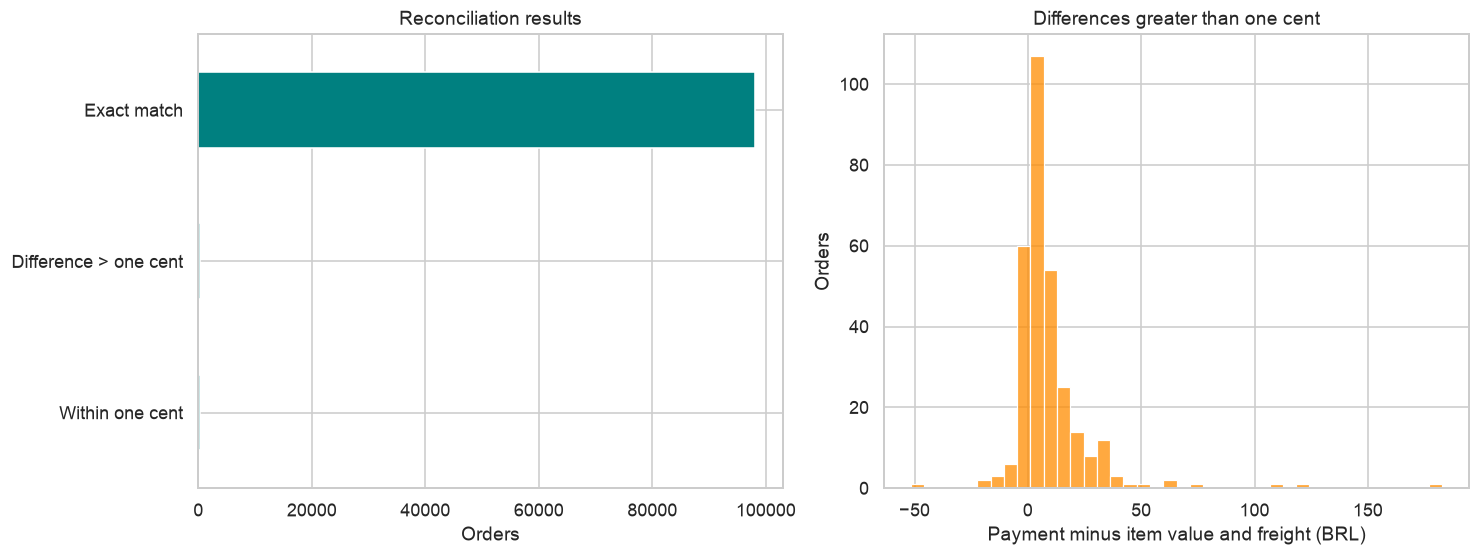

In [36]:
plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
reconciliation['Class'].value_counts().sort_values().plot(kind='barh', color='teal')
plt.title('Reconciliation results')
plt.xlabel('Orders')
plt.ylabel('')
plt.subplot(1, 2, 2)
sns.histplot(different, bins=40, color='darkorange')
plt.title('Differences greater than one cent')
plt.xlabel('Payment minus item value and freight (BRL)')
plt.ylabel('Orders')
plt.tight_layout()
plt.show()


Differences are reported rather than corrected. Missing sides are not zero. The files do not explain every mismatch, so we cannot assume refunds, discounts or timing are responsible.

## 10. Explore products and categories

Join the category translation to the product table first. A missing translation keeps the original Portuguese category; a missing category gets a display label. This is only a label for summaries and plots, not a source-data edit.


In [37]:
product_lookup = products.merge(translation, on='product_category_name', how='left', validate='many_to_one')
product_lookup['category_display'] = product_lookup['product_category_name_english']
product_lookup['category_display'] = product_lookup['category_display'].fillna(product_lookup['product_category_name'])
product_lookup['category_display'] = product_lookup['category_display'].fillna('Unknown category')

item_view = items.merge(product_lookup, on='product_id', how='left', validate='many_to_one')
purchase_dates = orders[['order_id', 'order_purchase_timestamp']]
item_view = item_view.merge(purchase_dates, on='order_id', how='left', validate='many_to_one')
assert len(item_view) == len(items)

category_summary = item_view.groupby('category_display').agg(
    item_lines=('order_id', 'size'),
    orders=('order_id', 'nunique'),
    products=('product_id', 'nunique'),
    item_value=('price', 'sum'),
    freight=('freight_value', 'sum')
)
category_summary = category_summary.sort_values('item_value', ascending=False)
display(category_summary.head(15).round(2))
assert np.isclose(category_summary['item_value'].sum(), items['price'].sum())


,item_lines,orders,products,item_value,freight
category_display,,,,,
health_beauty,9670,8836,2444,1258681.34,182566.73
watches_gifts,5991,5624,1329,1205005.68,100535.93
bed_bath_table,11115,9417,3029,1036988.68,204693.04
sports_leisure,8641,7720,2867,988048.97,168607.51
computers_accessories,7827,6689,1639,911954.32,147318.08
furniture_decor,8334,6449,2657,729762.49,172749.30
cool_stuff,3796,3632,789,635290.85,84039.10
housewares,6964,5884,2335,632248.66,146149.11
auto,4235,3897,1900,592720.11,92664.21


Top 10 categories, share of item value (%): 62.4
Smallest category order count: 2
Largest category order count: 9417


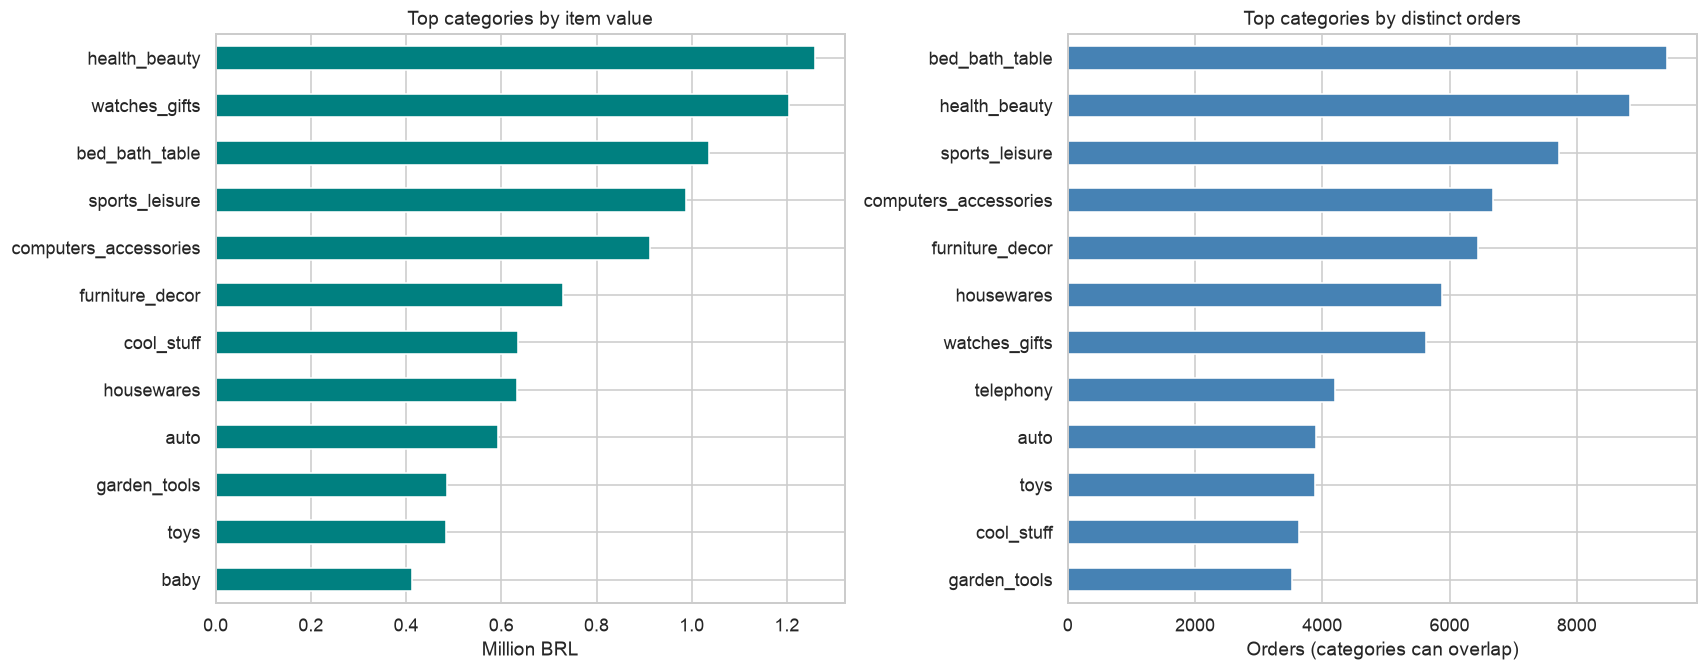

In [38]:
top_category_values = category_summary['item_value'].head(12) / 1000000
top_category_orders = category_summary['orders'].sort_values(ascending=False).head(12)

plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 1)
top_category_values.sort_values().plot(kind='barh', color='teal')
plt.title('Top categories by item value')
plt.xlabel('Million BRL')
plt.ylabel('')
plt.subplot(1, 2, 2)
top_category_orders.sort_values().plot(kind='barh', color='steelblue')
plt.title('Top categories by distinct orders')
plt.xlabel('Orders (categories can overlap)')
plt.ylabel('')
plt.tight_layout()
plt.show()

top_10_category_share = category_summary['item_value'].head(10).sum() / category_summary['item_value'].sum() * 100
print('Top 10 categories, share of item value (%):', round(top_10_category_share, 1))
print('Smallest category order count:', category_summary['orders'].min())
print('Largest category order count:', category_summary['orders'].max())


Category item values add up to the source total, including unknown categories. Category order counts do not add up to company orders because a basket can include several categories. Very small categories do not support stable rate comparisons.


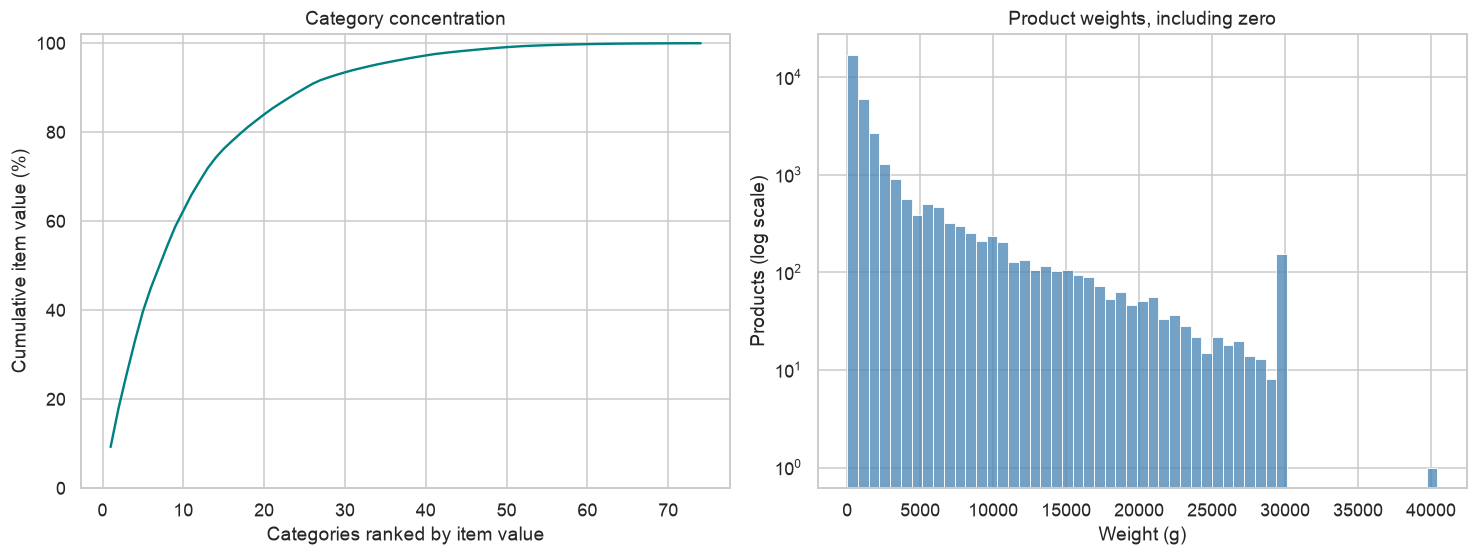

,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,32341.00,32341.00,32341.00,32949.00,32949.00,32949.00,32949.00
mean,48.48,771.50,2.19,2276.47,30.82,16.94,23.20
std,10.25,635.12,1.74,4282.04,16.91,13.64,12.08
min,5.00,4.00,1.00,0.00,7.00,2.00,6.00
50%,51.00,595.00,1.00,700.00,25.00,13.00,20.00
90%,59.00,1578.00,5.00,6300.00,53.00,33.00,40.00
99%,63.00,3286.20,8.00,22538.00,100.00,69.00,63.00
max,76.00,3992.00,20.00,40425.00,105.00,105.00,118.00


In [39]:
category_values = category_summary['item_value']
cumulative_category_share = category_values.cumsum() / category_values.sum() * 100
category_rank = range(1, len(category_values) + 1)

plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
plt.plot(category_rank, cumulative_category_share, color='teal')
plt.title('Category concentration')
plt.xlabel('Categories ranked by item value')
plt.ylabel('Cumulative item value (%)')
plt.ylim(0, 102)
plt.subplot(1, 2, 2)
sns.histplot(products['product_weight_g'].dropna(), bins=55, color='steelblue')
plt.yscale('log')
plt.title('Product weights, including zero')
plt.xlabel('Weight (g)')
plt.ylabel('Products (log scale)')
plt.tight_layout()
plt.show()

product_numeric = ['product_name_lenght', 'product_description_lenght', 'product_photos_qty',
                   'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
display(products[product_numeric].describe(percentiles=[0.5, 0.9, 0.99]).round(2))


Item lines shown: 112241
Item lines excluded from this plot only: 409


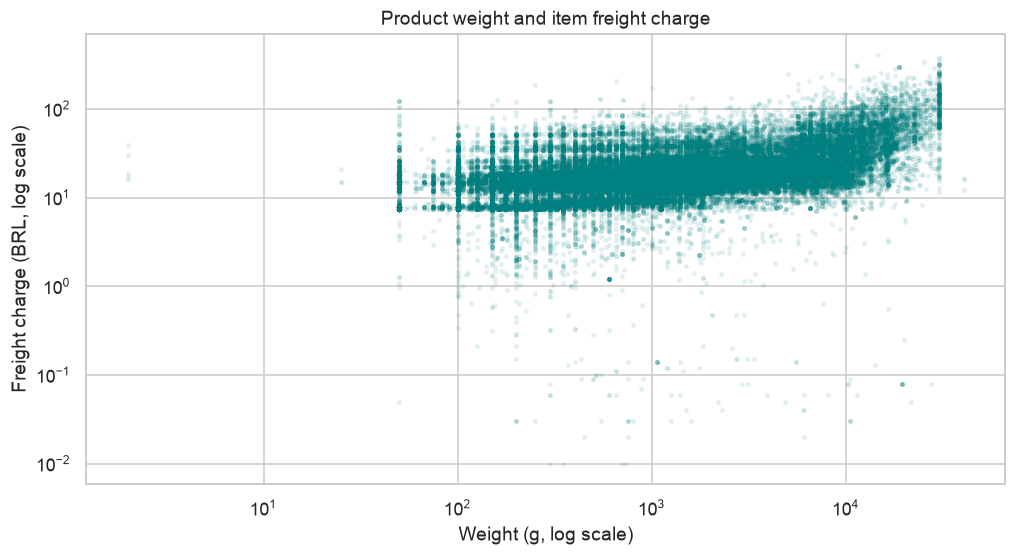

In [40]:
positive_weight_and_freight = (item_view['product_weight_g'] > 0) & (item_view['freight_value'] > 0)
weight_plot = item_view.loc[positive_weight_and_freight]

plt.figure(figsize=(9, 5))
plt.scatter(weight_plot['product_weight_g'], weight_plot['freight_value'], s=5, alpha=0.08, color='teal')
plt.xscale('log')
plt.yscale('log')
plt.title('Product weight and item freight charge')
plt.xlabel('Weight (g, log scale)')
plt.ylabel('Freight charge (BRL, log scale)')
plt.tight_layout()
plt.show()
print('Item lines shown:', len(weight_plot))
print('Item lines excluded from this plot only:', len(item_view) - len(weight_plot))


Product metadata are static snapshots. The weight plot excludes only rows without positive weight and freight; all applicable totals still retain them. Original column spelling, including `lenght`, is preserved. Weight and dimensions alone cannot explain freight pricing.

## 11. Explore sellers

Count distinct orders per seller and sum each item line once. An order involving multiple sellers contributes to more than one seller's order count, so those counts are not additive. The dataset does not identify which seller caused an order-level delivery delay.


In [41]:
seller_activity = items.groupby('seller_id').agg(
    item_value=('price', 'sum'),
    item_lines=('order_id', 'size'),
    orders=('order_id', 'nunique')
)
seller_activity = seller_activity.sort_values('item_value', ascending=False)
seller_states = sellers[['seller_id', 'seller_state']]
seller_activity = seller_activity.merge(seller_states, on='seller_id', how='left', validate='one_to_one')

seller_values = seller_activity['item_value'].sort_values(ascending=False)
cumulative_seller_share = seller_values.cumsum() / seller_values.sum() * 100
seller_rank = range(1, len(seller_values) + 1)
sellers_per_order = item_by_order['seller_count'].value_counts().sort_index()

seller_state_summary = seller_activity.groupby('seller_state').agg(
    sellers=('seller_id', 'size'),
    item_value=('item_value', 'sum')
)
seller_state_summary = seller_state_summary.sort_values('item_value', ascending=False)
display(seller_state_summary.head(12).round(2))


,sellers,item_value
seller_state,,
SP,1849,8753396.21
PR,349,1261887.21
MG,244,1011564.74
RJ,171,843984.22
SC,190,632426.07
RS,129,378559.54
BA,19,285561.56
DF,30,97749.48
PE,9,91493.85


Multi-seller orders: 1278
Top 10 sellers, share of item value (%): 13.1


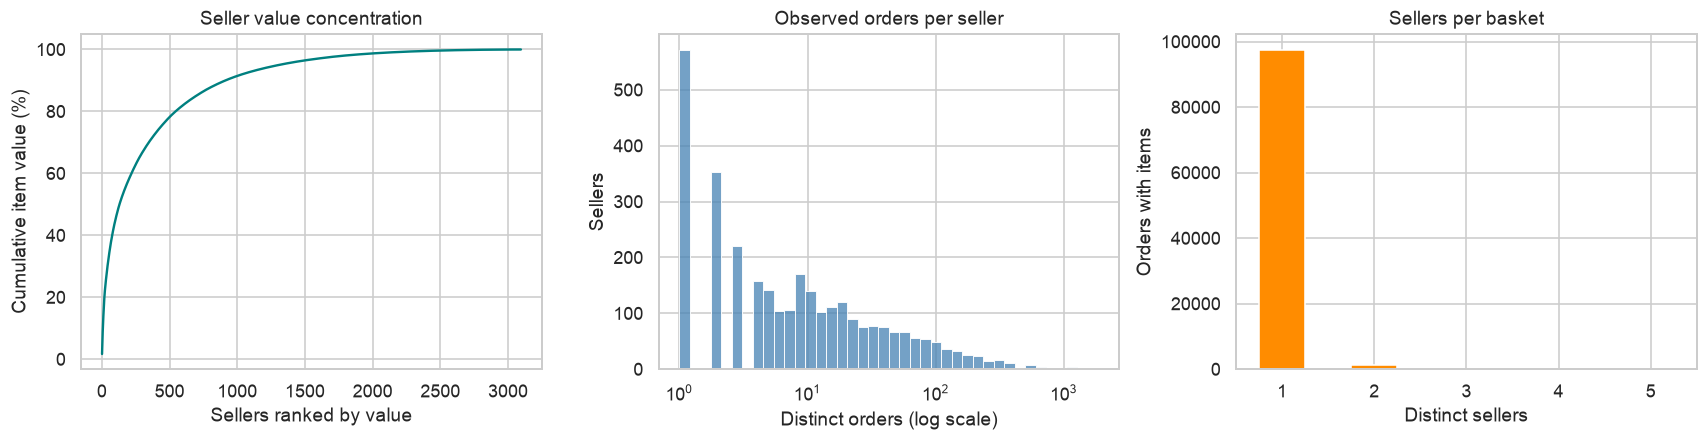

In [42]:
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.plot(seller_rank, cumulative_seller_share, color='teal')
plt.title('Seller value concentration')
plt.xlabel('Sellers ranked by value')
plt.ylabel('Cumulative item value (%)')
plt.subplot(1, 3, 2)
sns.histplot(seller_activity['orders'], bins=40, log_scale=True, color='steelblue')
plt.title('Observed orders per seller')
plt.xlabel('Distinct orders (log scale)')
plt.ylabel('Sellers')
plt.subplot(1, 3, 3)
sellers_per_order.plot(kind='bar', color='darkorange', rot=0)
plt.title('Sellers per basket')
plt.xlabel('Distinct sellers')
plt.ylabel('Orders with items')
plt.tight_layout()
plt.show()

multi_seller_orders = (item_by_order['seller_count'] > 1).sum()
top_10_seller_share = seller_values.head(10).sum() / seller_values.sum() * 100
print('Multi-seller orders:', multi_seller_orders)
print('Top 10 sellers, share of item value (%):', round(top_10_seller_share, 1))


## 12. Explore customers and repeat purchases

Use `customer_unique_id` to connect purchases by the same observed buyer. One purchase in this snapshot does not prove churn or disloyalty. There is no customer segmentation, lifetime-value estimation or prediction.


In [43]:
buyer_summary = order_view.groupby('customer_unique_id').agg(
    orders=('order_id', 'size'),
    first_purchase=('order_purchase_timestamp', 'min'),
    last_purchase=('order_purchase_timestamp', 'max')
)
# Keep an all-missing buyer item total unknown instead of zero.
buyer_summary['item_value'] = order_view.groupby('customer_unique_id')['item_value'].sum(min_count=1)
buyer_summary['frequency_group'] = pd.cut(buyer_summary['orders'],
                                         bins=[0, 1, 2, 3, np.inf], labels=['1', '2', '3', '4+'])
frequency = buyer_summary['frequency_group'].value_counts(sort=False)

ordered_purchases = order_view.sort_values(['customer_unique_id', 'order_purchase_timestamp'])
gaps = ordered_purchases.groupby('customer_unique_id')['order_purchase_timestamp'].diff()
gaps = gaps.dt.total_seconds() / 86400
repeat_buyers = (buyer_summary['orders'] > 1).sum()
repeat_share = repeat_buyers / len(buyer_summary) * 100
print('Observed buyers:', len(buyer_summary))
print('Buyers with more than one order:', repeat_buyers)
print('Observed repeat share (%):', round(repeat_share, 2))


Observed buyers: 96096
Buyers with more than one order: 2997
Observed repeat share (%): 3.12


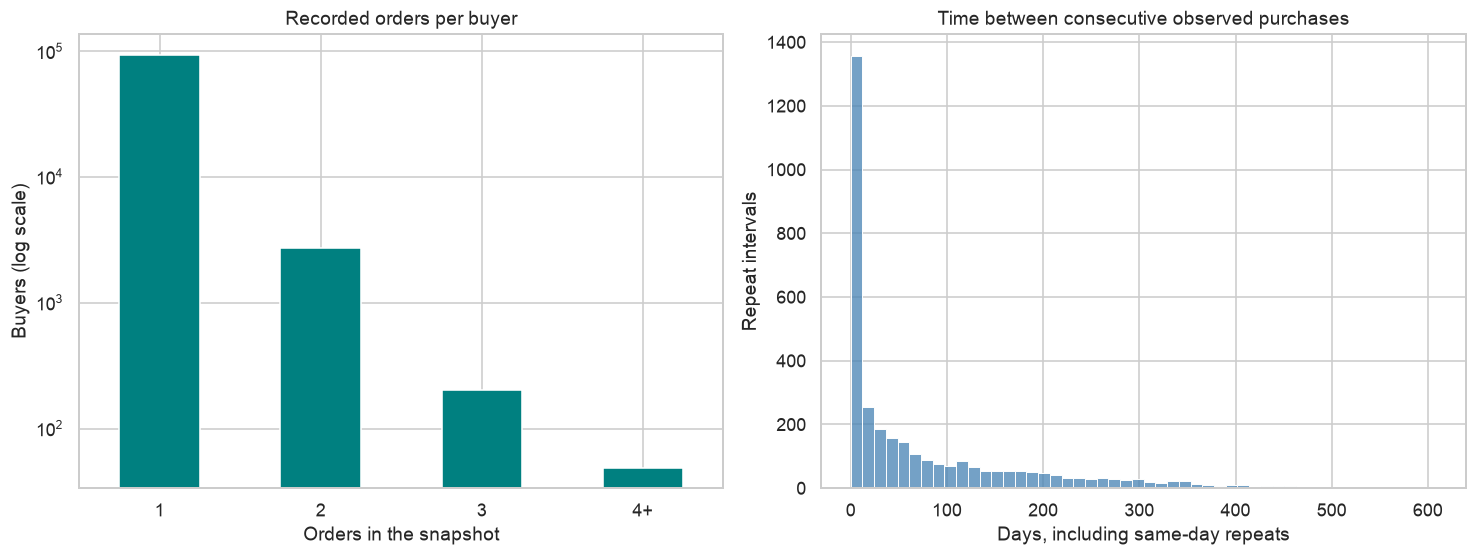

In [44]:
plt.figure(figsize=(13, 5))
plt.subplot(1, 2, 1)
frequency.plot(kind='bar', color='teal', rot=0)
plt.yscale('log')
plt.title('Recorded orders per buyer')
plt.xlabel('Orders in the snapshot')
plt.ylabel('Buyers (log scale)')
plt.subplot(1, 2, 2)
sns.histplot(gaps.dropna(), bins=50, color='steelblue')
plt.title('Time between consecutive observed purchases')
plt.xlabel('Days, including same-day repeats')
plt.ylabel('Repeat intervals')
plt.tight_layout()
plt.show()


### Compare repeat behavior within a common 90-day window

This section has a few more steps because customers need comparable follow-up:
1. Find each buyer's first recorded purchase.
2. Keep buyers whose 90-day window ends before September 2018.
3. Count their orders within that window.
4. Report the share with more than one order, grouped by first-observed month.

This matches the original notebook's definition. First observed is not necessarily acquisition, and data capture may be incomplete. Later buyers are excluded only from this comparison.


In [45]:
comparison_end = pd.Timestamp('2018-09-01')
first_purchase = buyer_summary['first_purchase']
window_end = first_purchase + pd.Timedelta(days=90)
eligible_buyer = (first_purchase >= '2017-01-01') & (window_end < comparison_end)

first_seen = buyer_summary[['first_purchase']].copy()
first_seen = first_seen.rename(columns={'first_purchase': 'first_seen'})
with_first = order_view[['customer_unique_id', 'order_purchase_timestamp']].copy()
with_first = with_first.merge(first_seen, on='customer_unique_id', how='left', validate='many_to_one')

within_90 = (with_first['order_purchase_timestamp'] >= with_first['first_seen']) & (with_first['order_purchase_timestamp'] <= with_first['first_seen'] + pd.Timedelta(days=90))
orders_in_window = with_first.loc[within_90]
count_90 = orders_in_window.groupby('customer_unique_id').size()


Buyers with an eligible 90-day window: 77799


,buyers,repeat_buyers,repeat_pct
cohort,,,
2017-01,764,30,3.93
2017-02,1752,31,1.77
2017-03,2636,67,2.54
2017-04,2352,50,2.13
2017-05,3596,107,2.98
2017-06,3139,93,2.96
2017-07,3894,105,2.70
2017-08,4184,118,2.82
2017-09,4130,121,2.93


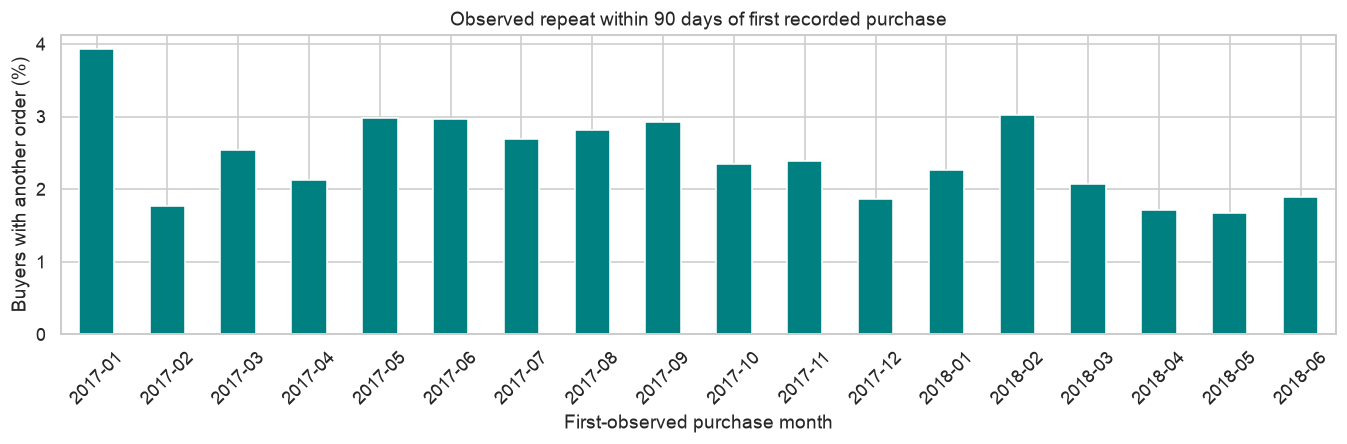

In [46]:
cohort_buyers = buyer_summary.loc[eligible_buyer].copy()
cohort_buyers['cohort'] = cohort_buyers['first_purchase'].dt.to_period('M').astype(str)
cohort_buyers['repeat_within_90'] = count_90.reindex(cohort_buyers.index) > 1

cohort_repeat = cohort_buyers.groupby('cohort').agg(
    buyers=('orders', 'size'),
    repeat_buyers=('repeat_within_90', 'sum')
)
cohort_repeat['repeat_pct'] = cohort_repeat['repeat_buyers'] / cohort_repeat['buyers'] * 100
display(cohort_repeat.round(2))
print('Buyers with an eligible 90-day window:', len(cohort_buyers))

plt.figure(figsize=(12, 4))
cohort_repeat['repeat_pct'].plot(kind='bar', color='teal', rot=45)
plt.title('Observed repeat within 90 days of first recorded purchase')
plt.xlabel('First-observed purchase month')
plt.ylabel('Buyers with another order (%)')
plt.tight_layout()
plt.show()


The last eligible month can contain only part of its first-purchase dates; use the displayed buyer counts when comparing cohorts. The full-snapshot repeat share and this fixed-window measure answer different questions.

## 13. Explore geography

Customer state is the destination; seller state is a separate measure. For state late-rate charts, show the eligible-delivery denominator and avoid ranking very small groups. Every state remains in the table.


In [47]:
state_summary = order_view.groupby('customer_state').agg(orders=('order_id', 'size'))
state_summary['item_value'] = order_view.groupby('customer_state')['item_value'].sum(min_count=1)
state_delivery = deliveries.groupby('customer_state').agg(
    eligible_deliveries=('order_id', 'size'),
    late=('late_calendar', 'sum'),
    median_delivery_days=('delivery_days', 'median')
)
state_summary = state_summary.join(state_delivery)
state_summary['late_pct'] = state_summary['late'] / state_summary['eligible_deliveries'] * 100
display(state_summary.round(2))

top_states = state_summary['orders'].sort_values(ascending=False).head(15)
supported_states = state_summary.loc[state_summary['eligible_deliveries'] >= 300].copy()
supported_states = supported_states.sort_values('late_pct', ascending=False).head(15)
# Include the denominator directly in the plot label.
supported_states['label'] = supported_states.index + ' (n=' + supported_states['eligible_deliveries'].astype(int).astype(str) + ')'
state_rates = supported_states.set_index('label')['late_pct']


,orders,item_value,eligible_deliveries,late,median_delivery_days,late_pct
customer_state,,,,,,
AC,81,15982.95,80,3,18.36,3.75
AL,413,80314.81,397,85,22.33,21.41
AM,148,22356.84,145,4,25.88,2.76
AP,68,13474.30,67,2,24.35,2.99
BA,3380,511349.99,3256,396,16.91,12.16
CE,1336,227254.71,1279,176,18.21,13.76
DF,2140,302603.94,2080,118,11.36,5.67
ES,2033,275037.31,1995,214,13.64,10.73
GO,2020,294591.95,1957,128,13.95,6.54


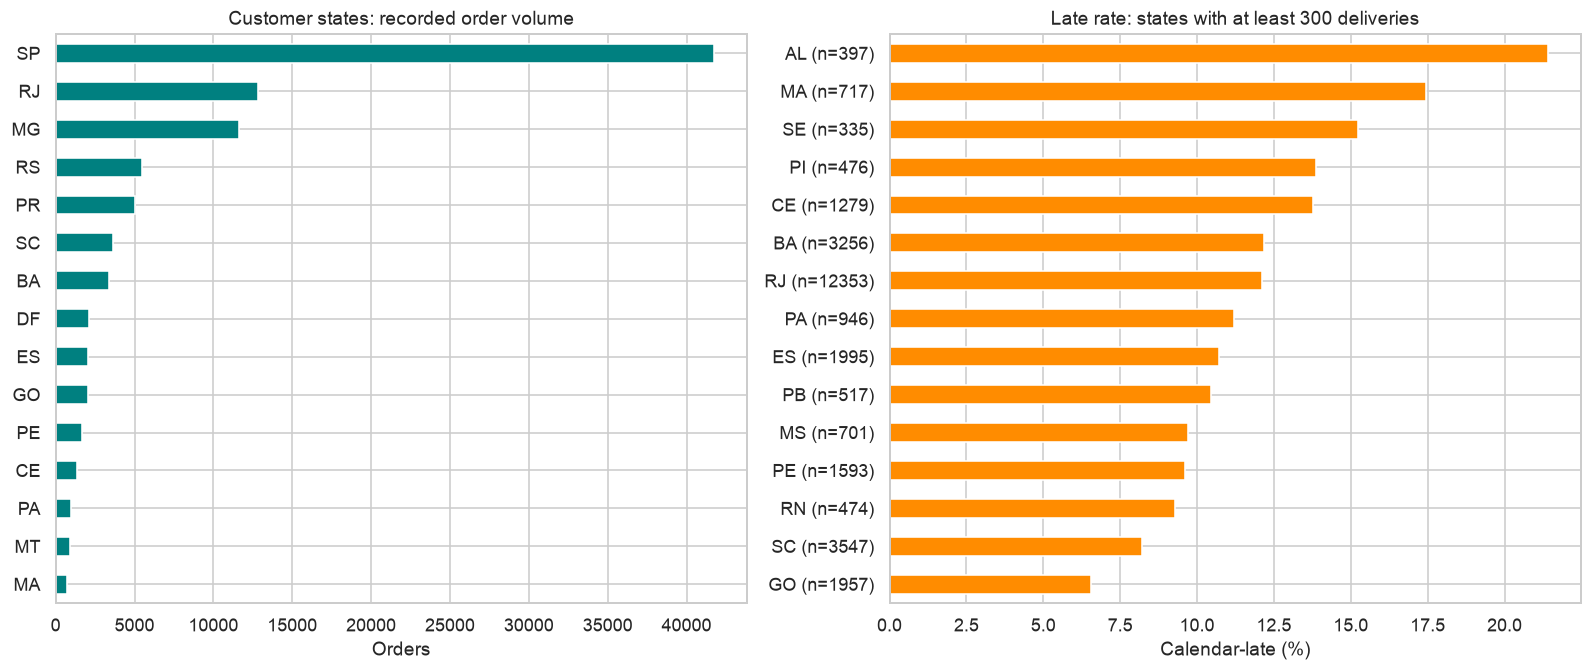

In [48]:
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
top_states.sort_values().plot(kind='barh', color='teal')
plt.title('Customer states: recorded order volume')
plt.xlabel('Orders')
plt.ylabel('')
plt.subplot(1, 2, 2)
state_rates.sort_values().plot(kind='barh', color='darkorange')
plt.title('Late rate: states with at least 300 deliveries')
plt.xlabel('Calendar-late (%)')
plt.ylabel('')
plt.tight_layout()
plt.show()


Rates are conditional on observed deliveries and are not adjusted for sellers, categories, time or distance. A 300-delivery display threshold is not a statistical significance test.

### Inspect the location table before plotting it

ZIP prefixes repeat in the raw geolocation file. A direct join would multiply orders. Check duplicated rows, conflicting state/city strings and a broad Brazil bounding box. The bounding box is a plotting screen, not an exact national boundary.


In [49]:
states_per_zip = geolocation.groupby('geolocation_zip_code_prefix')['geolocation_state'].nunique()
cities_per_zip = geolocation.groupby('geolocation_zip_code_prefix')['geolocation_city'].nunique()
latitude_ok = geolocation['geolocation_lat'].between(-34, 6)
longitude_ok = geolocation['geolocation_lng'].between(-74, -28)
in_box = latitude_ok & longitude_ok

geo_diagnostics = pd.DataFrame({
    'Check': ['Location rows', 'Exact duplicates', 'Distinct ZIP prefixes',
               'ZIPs with multiple states', 'ZIPs with multiple city strings',
               'Rows outside the broad bounding box'],
    'Count': [len(geolocation), geolocation.duplicated().sum(),
               geolocation['geolocation_zip_code_prefix'].nunique(),
               (states_per_zip > 1).sum(), (cities_per_zip > 1).sum(), (~in_box).sum()]
})
display(geo_diagnostics)


,Check,Count
0,Location rows,1000163
1,Exact duplicates,261831
2,Distinct ZIP prefixes,19015
3,ZIPs with multiple states,8
4,ZIPs with multiple city strings,8556
5,Rows outside the broad bounding box,31


### Build a plot-only ZIP summary

Use unique coordinate observations inside the box, then calculate one median latitude/longitude per ZIP. Join order counts to that summary. This does not alter source geography and does not create an exported cleaned table. ZIP medians are approximate, not household locations.


In [50]:
coordinate_columns = ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng']
geo_plot_source = geolocation.loc[in_box, coordinate_columns].copy()
geo_plot_source = geo_plot_source.drop_duplicates()
zip_plot = geo_plot_source.groupby('geolocation_zip_code_prefix').agg(
    latitude=('geolocation_lat', 'median'),
    longitude=('geolocation_lng', 'median')
)
zip_order_counts = order_view.groupby('customer_zip_code_prefix').size()
zip_order_counts.name = 'orders'
zip_plot = zip_plot.join(zip_order_counts, how='inner')

plotted_orders = zip_plot['orders'].sum()
print('Orders with a plot-eligible ZIP:', plotted_orders)
print('Orders without a plot-eligible ZIP:', len(order_view) - plotted_orders)


Orders with a plot-eligible ZIP: 99162
Orders without a plot-eligible ZIP: 279


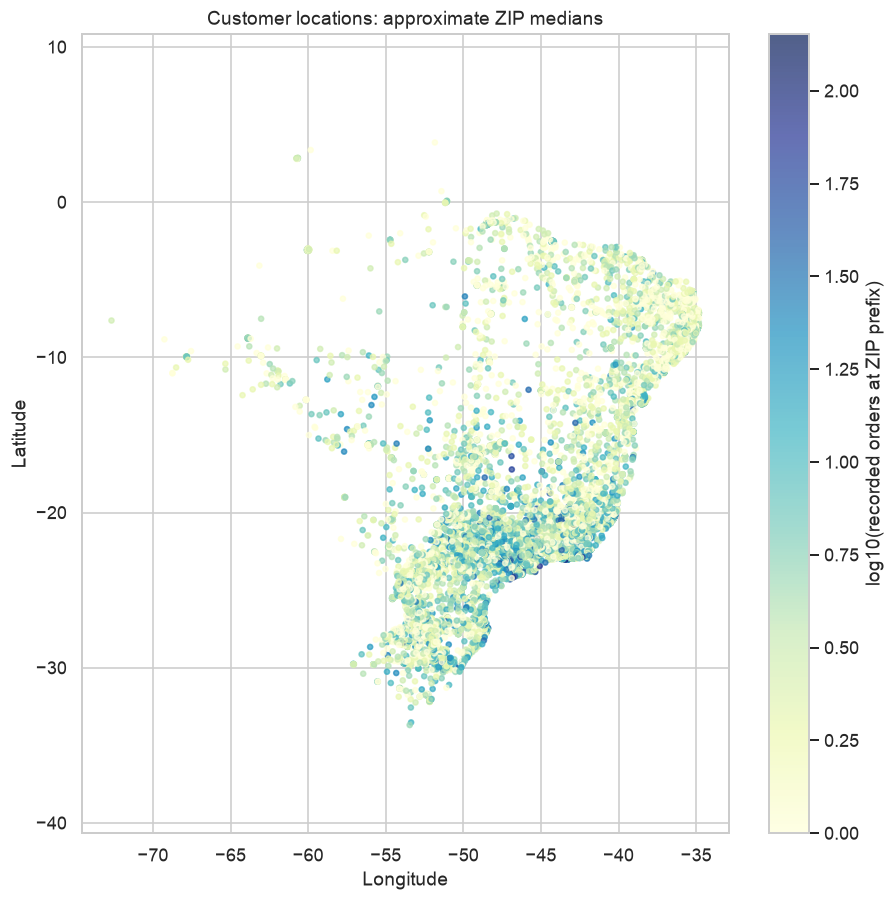

In [51]:
# Log color makes low-volume and high-volume ZIPs visible together.
plt.figure(figsize=(8, 8))
plt.scatter(zip_plot['longitude'], zip_plot['latitude'],
            c=np.log10(zip_plot['orders']), s=10, cmap='YlGnBu', alpha=0.7)
plt.colorbar(label='log10(recorded orders at ZIP prefix)')
plt.title('Customer locations: approximate ZIP medians')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.axis('equal')
plt.tight_layout()
plt.show()


This is a coordinate scatter without an external basemap. Out-of-box observations are excluded only from this plot. Missing and ambiguous locations do not disappear from the overall order totals or the state summaries.

## 14. Explore numeric associations

We use Spearman correlation to summarize relationships between numeric measurements. Choose a common complete-case group for this plot so all correlations have the same denominator. This is not a general missing-row deletion or feature-selection step.


Orders included in this plot: 95827
Orders outside this plot: 3614


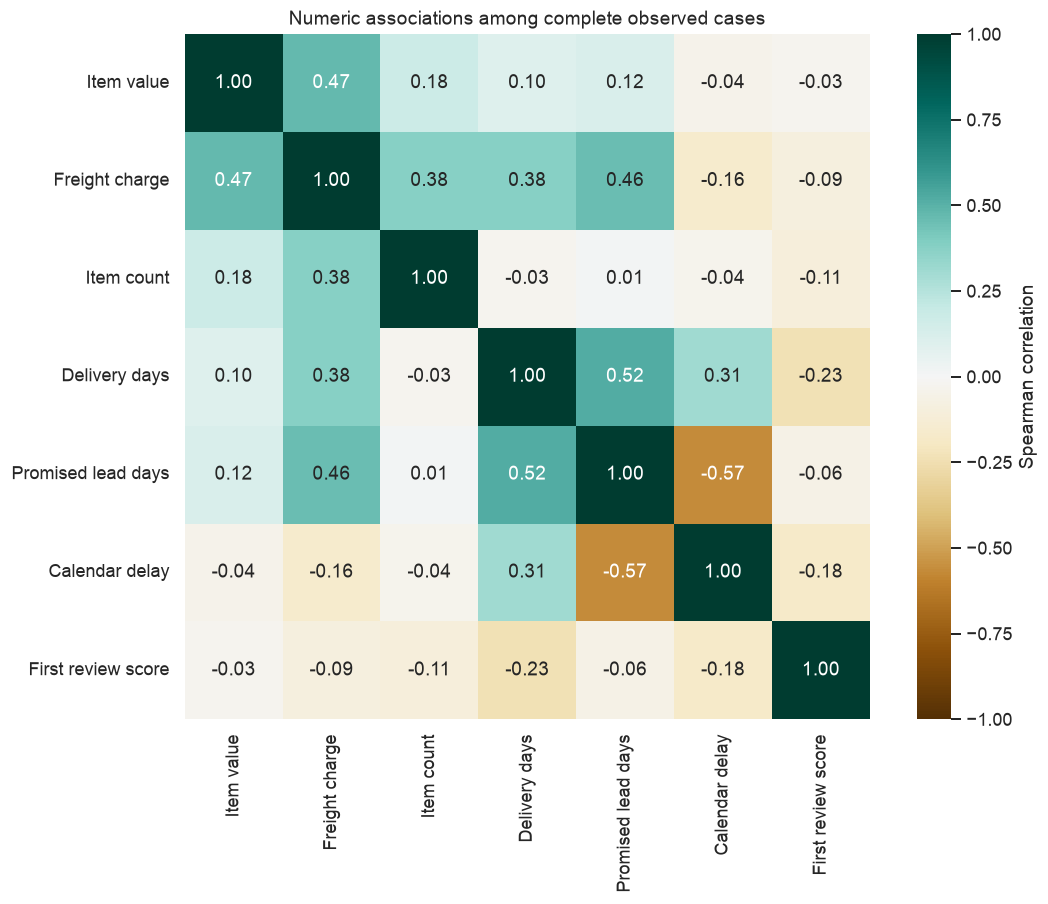

In [52]:
association_columns = ['item_value', 'freight_value', 'item_count', 'delivery_days',
                       'promise_days', 'delay_calendar_days', 'review_score']
association = deliveries[association_columns].copy()
association = association.dropna()
association.columns = ['Item value', 'Freight charge', 'Item count', 'Delivery days',
                        'Promised lead days', 'Calendar delay', 'First review score']
correlation = association.corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='BrBG', vmin=-1, vmax=1, center=0,
            square=True, cbar_kws={'label': 'Spearman correlation'})
plt.title('Numeric associations among complete observed cases')
plt.tight_layout()
plt.show()
print('Orders included in this plot:', len(association))
print('Orders outside this plot:', len(order_view) - len(association))


Correlation is not causation. Delivery duration and delay are partly mechanically related. Complete cases are selected toward delivered orders with respondents, so this is not automatically representative of all customers. These variables are descriptive measurements, not approved checkout-time model inputs.

## 15. Summarize findings and check the source files

The results below are calculated from the current run. No model has been trained or evaluated.


In [53]:
findings = pd.DataFrame({
    'Topic': ['Source files', 'Orders', 'Observed deliveries', 'Calendar-late deliveries',
               'Median delivery days', 'Valid first-review orders', 'Observed buyers',
               'Repeat buyers', 'Payment mismatches over one cent',
               'Top 10 category value share (%)', 'Orders with plot-eligible ZIP'],
    'Result': [len(tables), len(orders), len(deliveries), calendar_late.sum(),
                deliveries['delivery_days'].median(), len(first_review), len(buyer_summary),
                repeat_buyers, len(different), top_10_category_share, plotted_orders]
})
display(findings.round(2))


,Topic,Result
0,Source files,9.00
1,Orders,99441.00
2,Observed deliveries,96476.00
3,Calendar-late deliveries,6535.00
4,Median delivery days,10.22
5,Valid first-review orders,98613.00
6,Observed buyers,96096.00
7,Repeat buyers,2997.00
8,Payment mismatches over one cent,303.00
9,Top 10 category value share (%),62.36


### Main takeaways

- Correct table grain prevents duplicated orders and inflated money totals.
- The definition of lateness changes the measured late rate; missing outcomes remain unknown.
- Review timing and the choice of one answer per order change the relevant analysis group.
- Long-tailed order values, uneven category/seller activity and sparse repeat purchasing are visible patterns.
- Sparse periods, source anomalies and unequal observation windows limit comparisons.

### Limits

The files do not establish profit, inventory, refunds, settlement cash flow, true demand, customer lifetime value or causal effects. Final statuses cannot reconstruct every historical transition. This notebook does not prepare data for training.

### Final checks

Recheck the order grain and monetary totals, then compare file fingerprints. `assert` stops the notebook if a numerical consistency check fails. These are analysis checks, not a software test suite.


In [54]:
assert len(order_view) == len(orders)
assert order_view['order_id'].is_unique
assert np.isclose(order_view['item_value'].sum(), items['price'].sum())
assert np.isclose(order_view['freight_value'].sum(), items['freight_value'].sum())
assert np.isclose(order_view['payment_value'].sum(), payments['payment_value'].sum())
assert np.isclose(category_summary['item_value'].sum(), items['price'].sum())

for file in source_files:
    current_hash = hashlib.sha256(file.read_bytes()).hexdigest()
    assert current_hash == starting_hashes[file.name], 'Source changed: ' + file.name

print('PASS: one row per order and no inflated totals.')
print('PASS: source CSV files are unchanged.')
print('Complete: EDA and visualization only; no cleaned dataset export or model training.')

fingerprints = pd.DataFrame(list(starting_hashes.items()), columns=['Source file', 'SHA256'])
display(fingerprints)


PASS: one row per order and no inflated totals.
PASS: source CSV files are unchanged.
Complete: EDA and visualization only; no cleaned dataset export or model training.


,Source file,SHA256
0,olist_customers_dataset.csv,983a422239e1712ded753b3bf9ecf47dc73f144d306029...
1,olist_geolocation_dataset.csv,b514f6fc991b9566aeba02aa5d67e2c3630f034b60a0e0...
2,olist_order_items_dataset.csv,0bc4d068c4fe38cbb01bd90e8746e3c613fe7b4baef75f...
3,olist_order_payments_dataset.csv,4f713964f2815dbbaa40b9488268c55aac3627bfce5aa9...
4,olist_order_reviews_dataset.csv,012b61c7593e34f51fa614efdf802b9c7056ce6aae5307...
5,olist_orders_dataset.csv,8df58ef3d2d7e9944010f7beecd9b75367f5588ec6e3c9...
6,olist_products_dataset.csv,3e6569628a17fbc75fd206ee357b59e20364b9afa90f5b...
7,olist_sellers_dataset.csv,1f643d2b950373b85735e7794b20986f528d7a000432e7...
8,product_category_name_translation.csv,a81f0d1f27b27e7293f761bc79e3ce8f348ee39c4b3ed3...
